In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
sns.set()

import warnings



pd.set_option('display.max_rows', None)  # Display all rows


# **Importing the dataset and viewing the dataset**





In [ ]:
train_data = pd.read_csv("Housing-project-train-data.csv")

In [ ]:
train_data.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,127,120,RL,NaN,4928,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2007,WD,Normal,128000
1,889,20,RL,95.0,15865,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,10,2007,WD,Normal,268000
2,793,60,RL,92.0,9920,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,6,2007,WD,Normal,269790
3,110,20,RL,105.0,11751,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,1,2010,COD,Normal,190000
4,422,20,RL,NaN,16635,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,6,2009,WD,Normal,215000


In [ ]:
train_data.describe()


,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1168.000000,1168.000000,954.00000,1168.000000,1168.000000,1168.000000,1168.000000,1168.000000,1161.000000,1168.000000,...,1168.000000,1168.000000,1168.000000,1168.000000,1168.000000,1168.000000,1168.000000,1168.000000,1168.000000,1168.000000
mean,724.136130,56.767979,70.98847,10484.749144,6.104452,5.595890,1970.930651,1984.758562,102.310078,444.726027,...,96.206336,46.559932,23.015411,3.639555,15.051370,3.448630,47.315068,6.344178,2007.804795,181477.005993
std,416.159877,41.940650,24.82875,8957.442311,1.390153,1.124343,30.145255,20.785185,182.595606,462.664785,...,126.158988,66.381023,63.191089,29.088867,55.080816,44.896939,543.264432,2.686352,1.329738,79105.586863
min,1.000000,20.000000,21.00000,1300.000000,1.000000,1.000000,1875.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,360.500000,20.000000,60.00000,7621.500000,5.000000,5.000000,1954.000000,1966.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,130375.000000
50%,714.500000,50.000000,70.00000,9522.500000,6.000000,5.000000,1972.000000,1993.000000,0.000000,385.500000,...,0.000000,24.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163995.000000
75%,1079.500000,70.000000,80.00000,11515.500000,7.000000,6.000000,2000.000000,2004.000000,160.000000,714.500000,...,171.000000,70.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,215000.000000
max,1460.000000,190.000000,313.00000,164660.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [ ]:
train_data.dtypes

,0
Id,int64
MSSubClass,int64
MSZoning,object
LotFrontage,float64
LotArea,int64
Street,object
Alley,object
LotShape,object
LandContour,object
Utilities,object


In [ ]:
train_data.columns

Index(['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street',
       'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig',
       'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType',
       'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd',
       'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType',
       'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual',
       'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1',
       'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating',
       'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF',
       'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath',
       'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual',
       'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType',
       'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual',
       'GarageCond', 'PavedDrive

In [ ]:
train_data.drop(columns = "Id", inplace = True)

In [ ]:
train_data.nunique().to_frame("Number of unique values")

,Number of unique values
MSSubClass,15
MSZoning,5
LotFrontage,106
LotArea,892
Street,2
Alley,2
LotShape,4
LandContour,4
Utilities,1
LotConfig,5


In [ ]:
train_data.shape

(1168, 80)

# Splitting the features into numerical and categorical features

In [ ]:
numericalData_columns = train_data.select_dtypes(include=np.number)
categoricalData_columns = train_data.select_dtypes(include="object")

print("NUMERICAL COLUMNS:",numericalData_columns.columns)
print("==============================================================================")

print("CATEGORICAL COLUMNS:",categoricalData_columns.columns)


NUMERICAL COLUMNS: Index(['MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond',
       'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2',
       'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF',
       'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath',
       'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces',
       'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF',
       'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal',
       'MoSold', 'YrSold', 'SalePrice'],
      dtype='object')
CATEGORICAL COLUMNS: Index(['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities',
       'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2',
       'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st',
       'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation',
       'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', '

# Unique features of categorical features

In [ ]:
for i in categoricalData_columns:
  print(train_data[i].value_counts())
  print("-----------------------------------------------")

MSZoning
RL         928
RM         163
FV          52
RH          16
C (all)      9
Name: count, dtype: int64
-----------------------------------------------
Street
Pave    1164
Grvl       4
Name: count, dtype: int64
-----------------------------------------------
Alley
Grvl    41
Pave    36
Name: count, dtype: int64
-----------------------------------------------
LotShape
Reg    740
IR1    390
IR2     32
IR3      6
Name: count, dtype: int64
-----------------------------------------------
LandContour
Lvl    1046
Bnk      50
HLS      42
Low      30
Name: count, dtype: int64
-----------------------------------------------
Utilities
AllPub    1168
Name: count, dtype: int64
-----------------------------------------------
LotConfig
Inside     842
Corner     222
CulDSac     69
FR2         33
FR3          2
Name: count, dtype: int64
-----------------------------------------------
LandSlope
Gtl    1105
Mod      51
Sev      12
Name: count, dtype: int64
------------------------------------------

Here the feature "Utilities" has only one unique value so we drop this feature and update the "categoricalData_columns"

In [ ]:
train_data.drop(columns = "Utilities",inplace =  True)

In [ ]:
categoricalData_columns.drop(columns = "Utilities",inplace =  True)

In [ ]:
categoricalData_columns.columns

Index(['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'LotConfig',
       'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType',
       'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd',
       'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual',
       'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating',
       'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual', 'Functional',
       'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond',
       'PavedDrive', 'PoolQC', 'Fence', 'MiscFeature', 'SaleType',
       'SaleCondition'],
      dtype='object')

In [ ]:
train_data.shape

(1168, 79)

# **Exploratory Data Analysis**

In [ ]:
copied_data = train_data.copy()

# Detecting Duplicates

In [ ]:
copied_data.duplicated().sum()

0

# Detecting Missing Values

In [ ]:
train_data.isnull().sum()

,0
MSSubClass,0
MSZoning,0
LotFrontage,214
LotArea,0
Street,0
Alley,1091
LotShape,0
LandContour,0
LotConfig,0
LandSlope,0


In [ ]:
missing_features = [features  for features in train_data.columns  if train_data[features].isnull().sum() > 1]


In [ ]:
missing_features

['LotFrontage',
 'Alley',
 'MasVnrType',
 'MasVnrArea',
 'BsmtQual',
 'BsmtCond',
 'BsmtExposure',
 'BsmtFinType1',
 'BsmtFinType2',
 'FireplaceQu',
 'GarageType',
 'GarageYrBlt',
 'GarageFinish',
 'GarageQual',
 'GarageCond',
 'PoolQC',
 'Fence',
 'MiscFeature']

In [ ]:
train_data.shape

(1168, 79)

# Finding the Relationship between the missing feature and the target variable

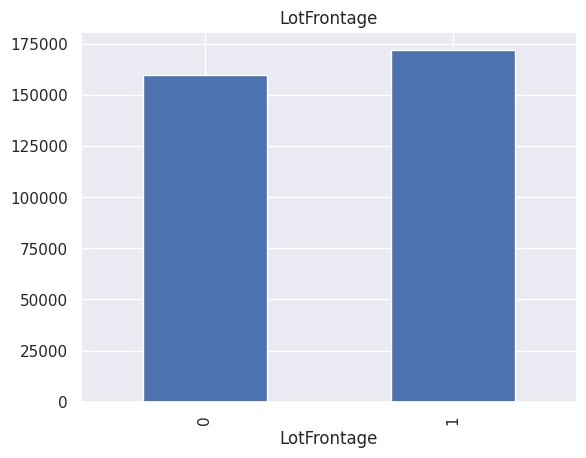

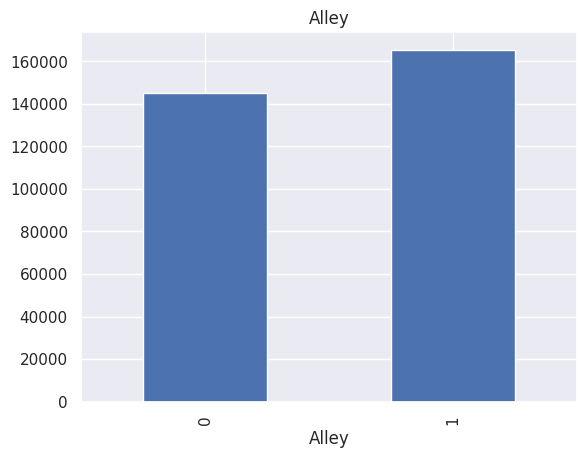

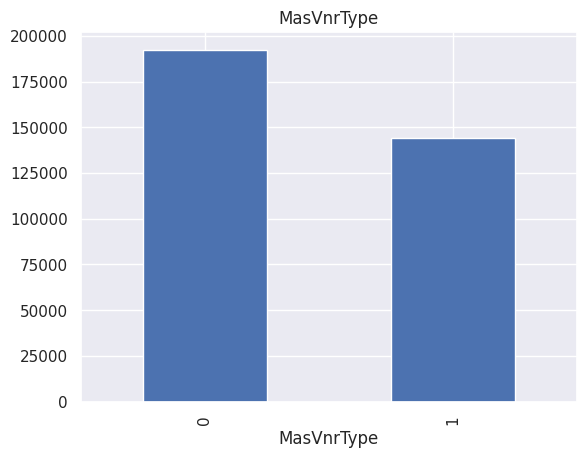

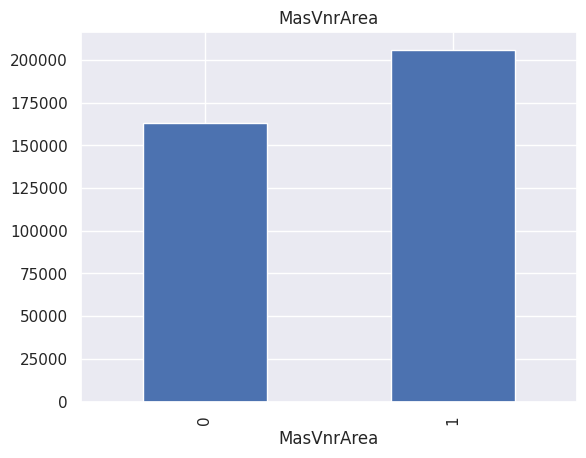

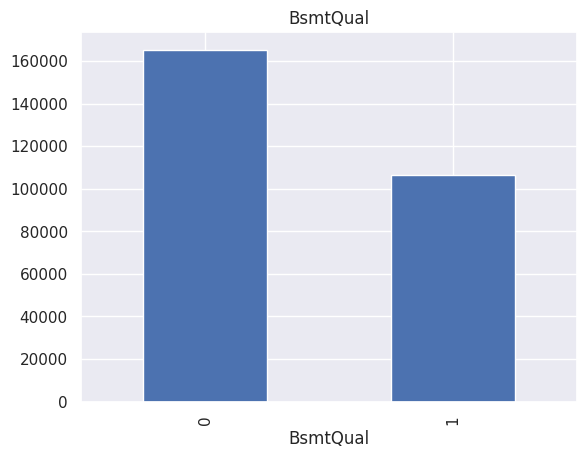

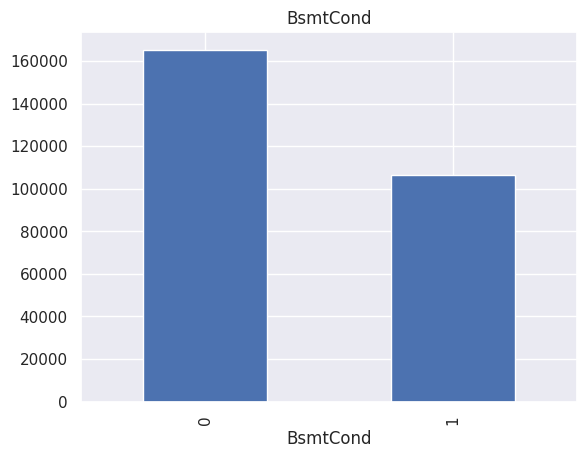

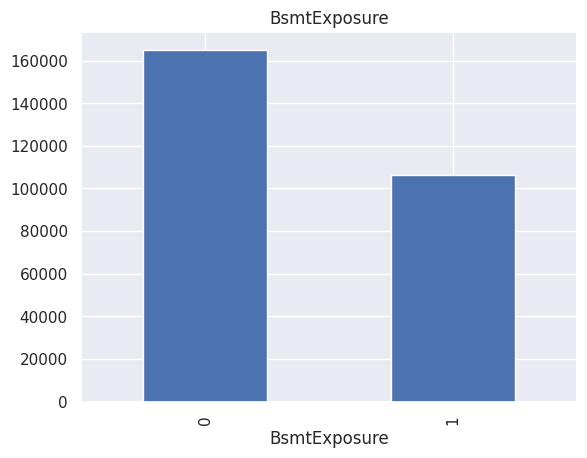

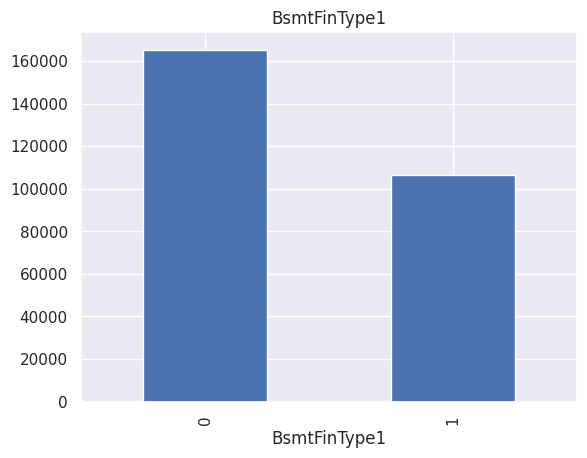

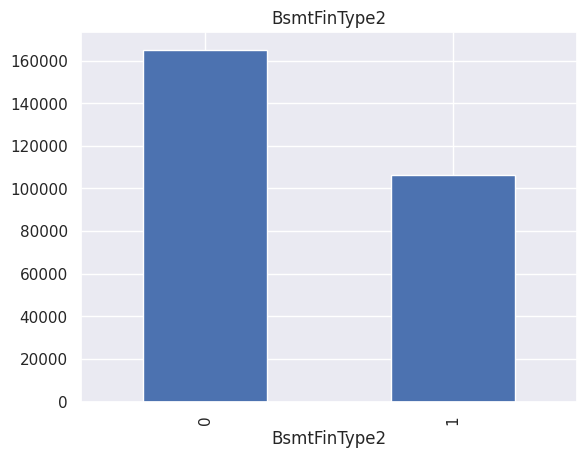

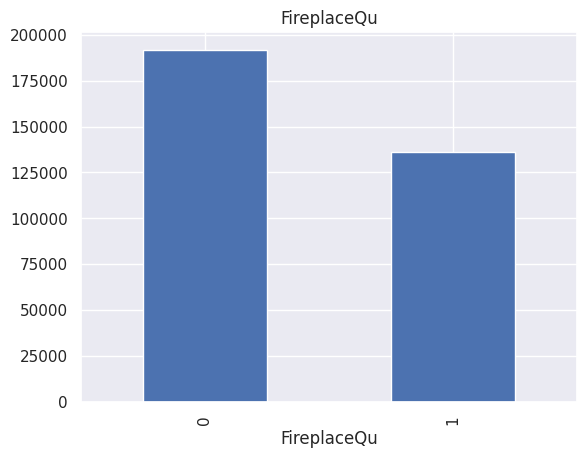

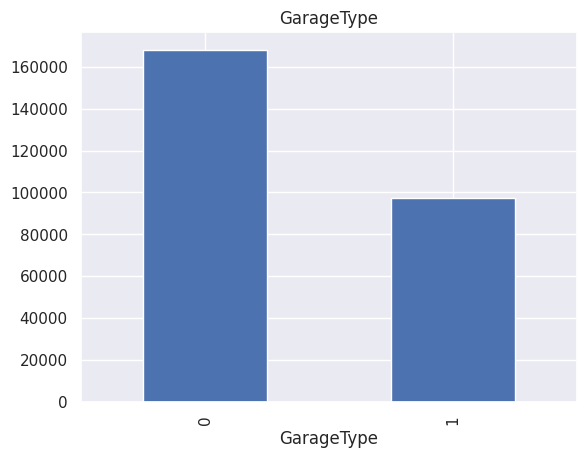

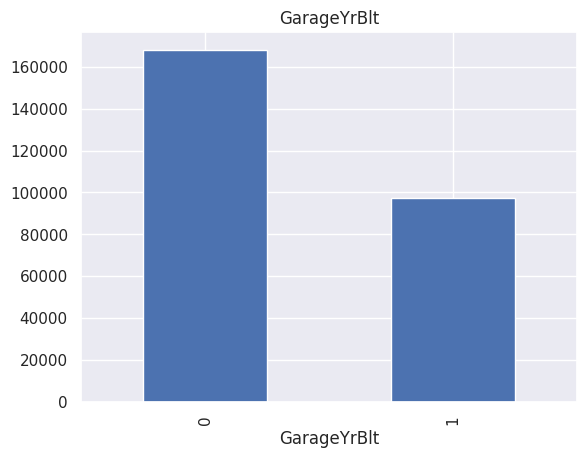

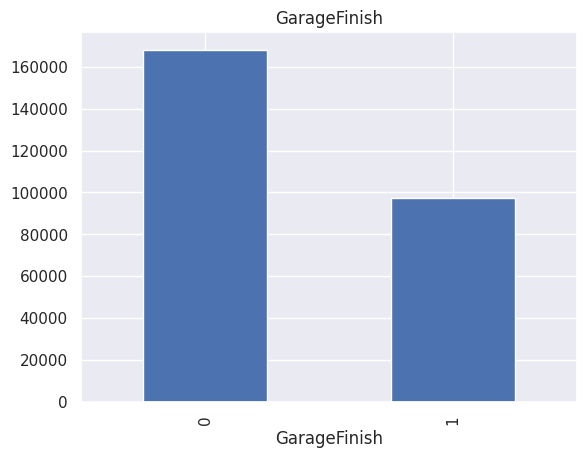

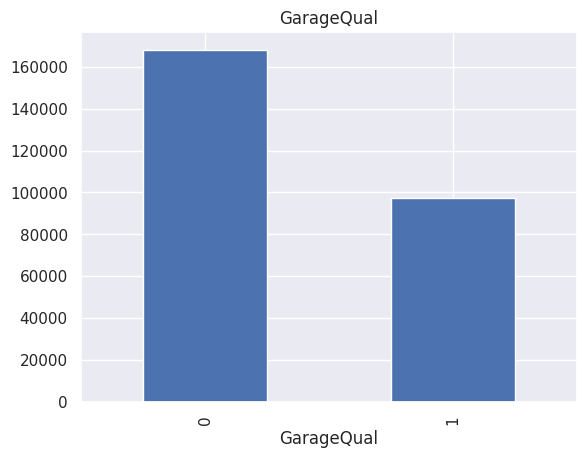

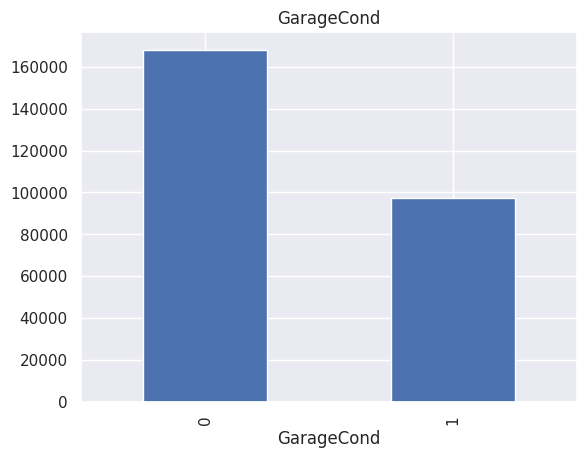

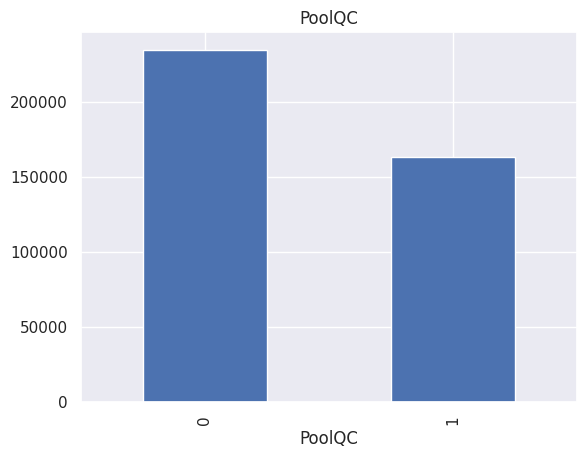

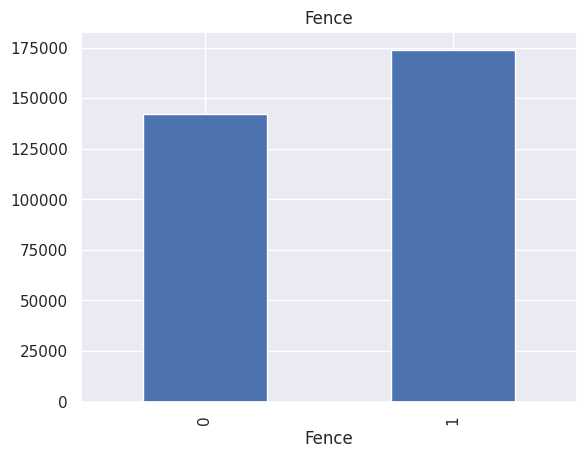

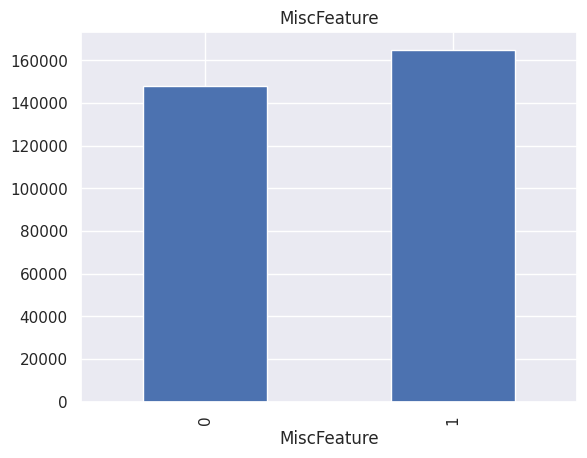

In [ ]:
for feature in missing_features:
    copied_data[feature] = np.where(copied_data[feature].isnull(),1,0)
    copied_data.groupby(feature)['SalePrice'].median().plot.bar()
    plt.title(feature)
    plt.show()

# Detecting Outliers of the target variable

<Axes: ylabel='SalePrice'>

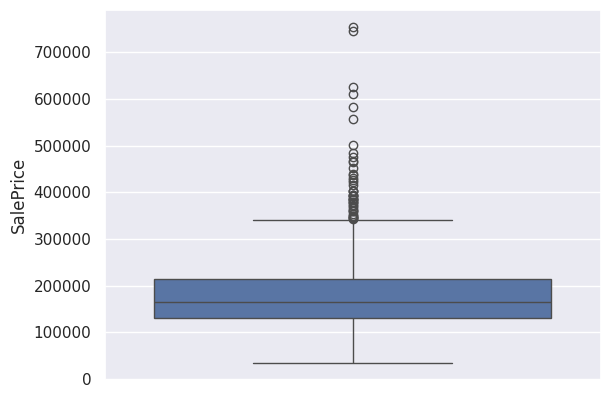

In [ ]:
sns.boxplot(copied_data["SalePrice"])

# Temporal Variables

In [ ]:
temporal = [i for i in numericalData_columns if "Yr" in i or "Year" in i ]
temporal

['YearBuilt', 'YearRemodAdd', 'GarageYrBlt', 'YrSold']

In [ ]:
train_data[temporal].head()

,YearBuilt,YearRemodAdd,GarageYrBlt,YrSold
0,1976,1976,1977.0,2007
1,1970,1970,1970.0,2007
2,1996,1997,1997.0,2007
3,1977,1977,1977.0,2010
4,1977,2000,1977.0,2009


In [ ]:
for i in temporal:
  print(i, len(copied_data[i].unique()))


YearBuilt 110
YearRemodAdd 61
GarageYrBlt 98
YrSold 5


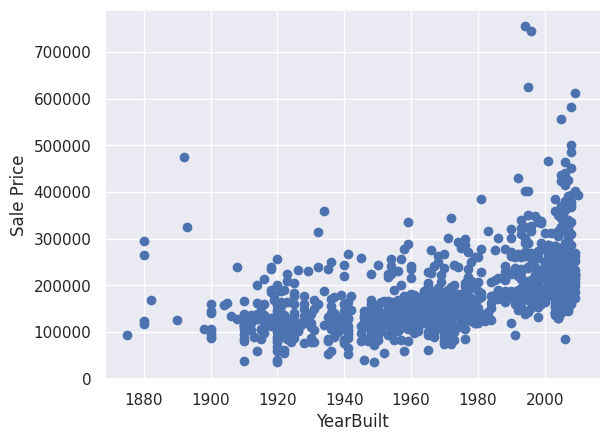

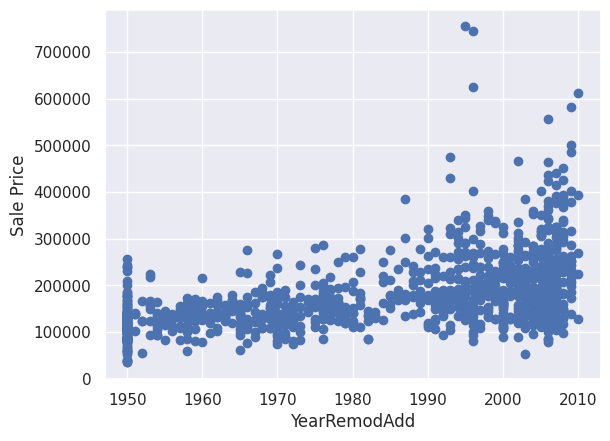

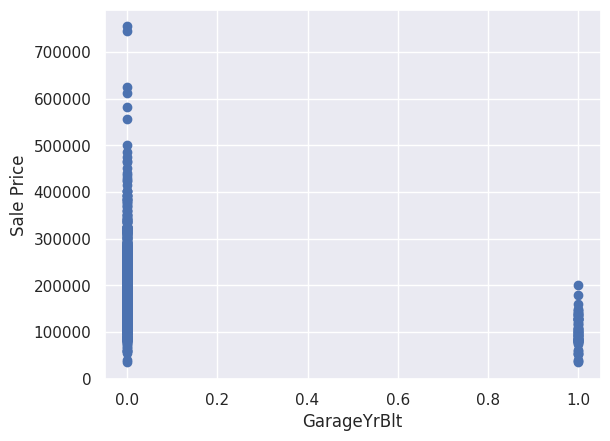

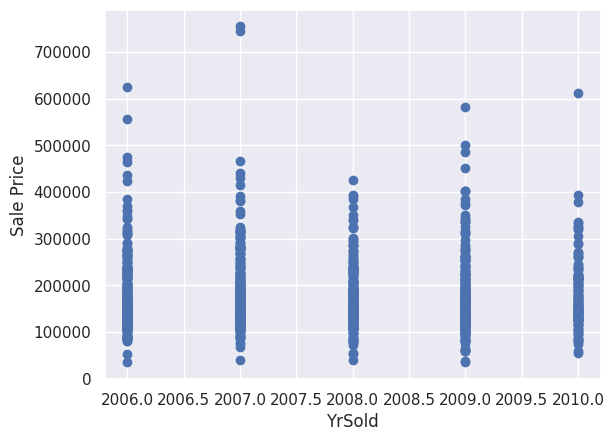

In [ ]:
for i in temporal:
  plt.scatter(copied_data[i], copied_data["SalePrice"])
  plt.xlabel(i)
  plt.ylabel("Sale Price")
  plt.show()

# Numerical Variables

In [ ]:
numericalData_columns.columns

Index(['MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond',
       'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2',
       'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF',
       'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath',
       'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces',
       'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF',
       'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal',
       'MoSold', 'YrSold', 'SalePrice'],
      dtype='object')

# Discrete Variable

In [ ]:
discrete = [i for i in numericalData_columns if len(copied_data[i].unique()) < 25]
discrete

['MSSubClass',
 'LotFrontage',
 'OverallQual',
 'OverallCond',
 'MasVnrArea',
 'LowQualFinSF',
 'BsmtFullBath',
 'BsmtHalfBath',
 'FullBath',
 'HalfBath',
 'BedroomAbvGr',
 'KitchenAbvGr',
 'TotRmsAbvGrd',
 'Fireplaces',
 'GarageYrBlt',
 'GarageCars',
 '3SsnPorch',
 'PoolArea',
 'MiscVal',
 'MoSold',
 'YrSold']

In [ ]:
copied_data[discrete].head()


,MSSubClass,LotFrontage,OverallQual,OverallCond,MasVnrArea,LowQualFinSF,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,...,KitchenAbvGr,TotRmsAbvGrd,Fireplaces,GarageYrBlt,GarageCars,3SsnPorch,PoolArea,MiscVal,MoSold,YrSold
0,120,1,6,5,0,0,0,0,2,0,...,1,5,1,0,2,0,0,0,2,2007
1,20,0,8,6,0,0,1,0,2,0,...,1,8,1,0,2,0,0,0,10,2007
2,60,0,7,5,0,0,1,0,2,1,...,1,8,1,0,2,0,0,0,6,2007
3,20,0,6,6,0,0,0,0,2,0,...,1,7,1,0,2,0,0,0,1,2010
4,20,1,6,7,0,0,0,1,2,0,...,1,8,1,0,2,0,0,0,6,2009


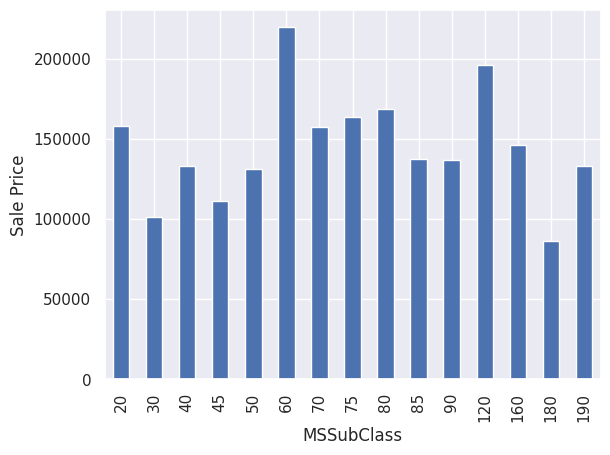

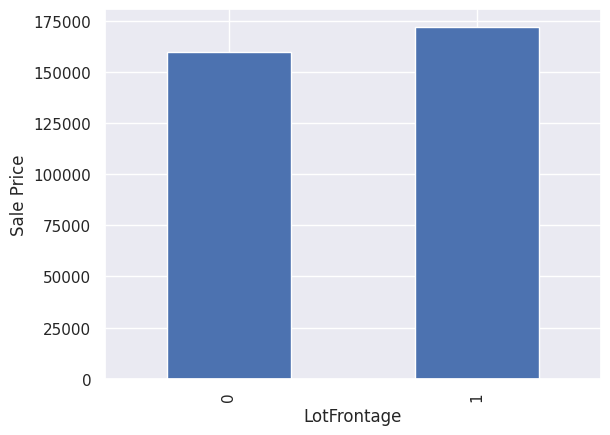

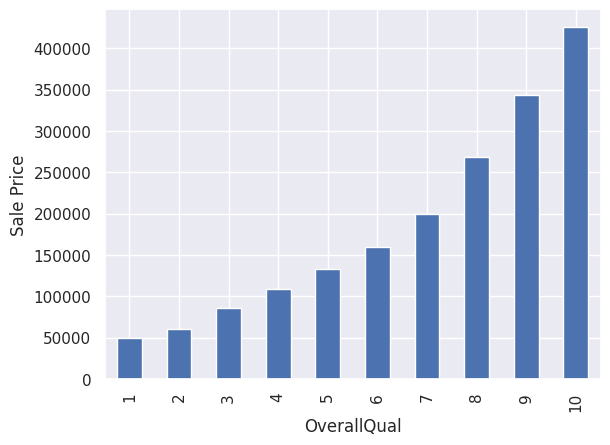

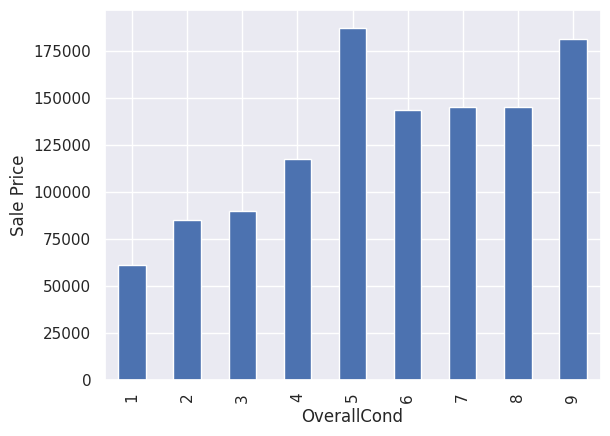

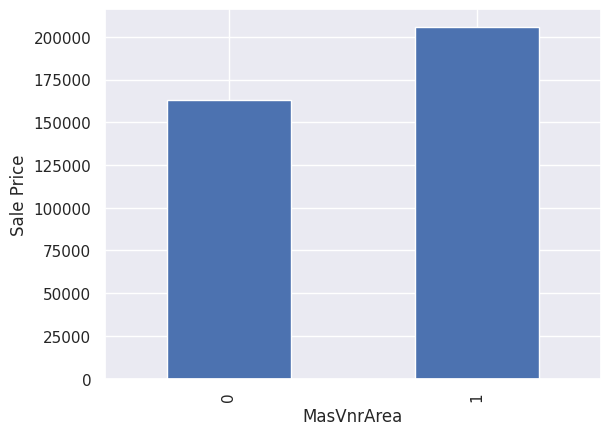

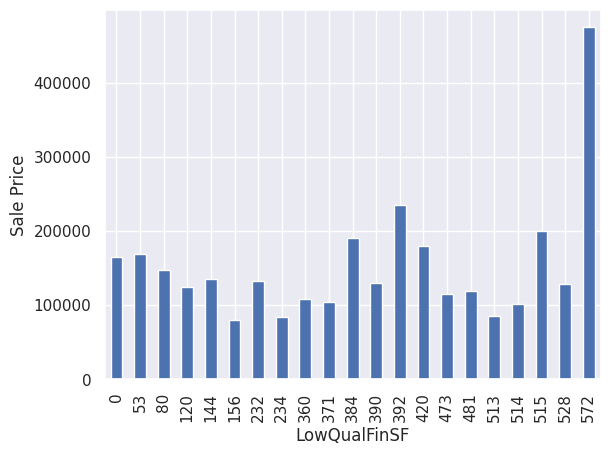

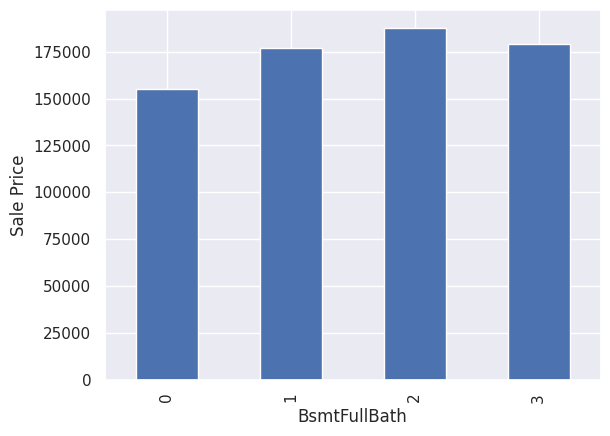

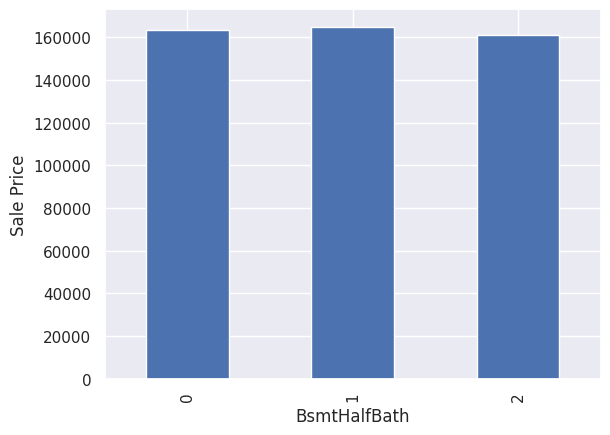

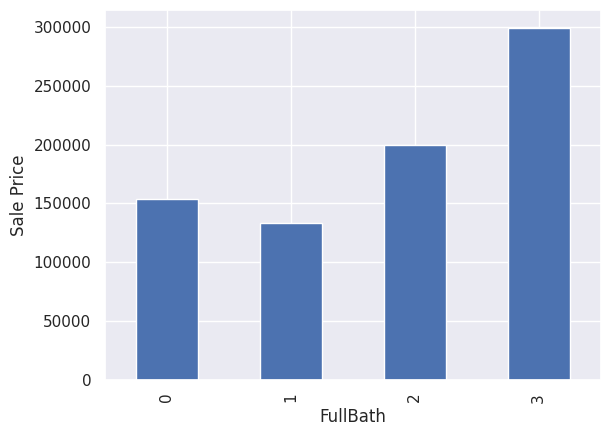

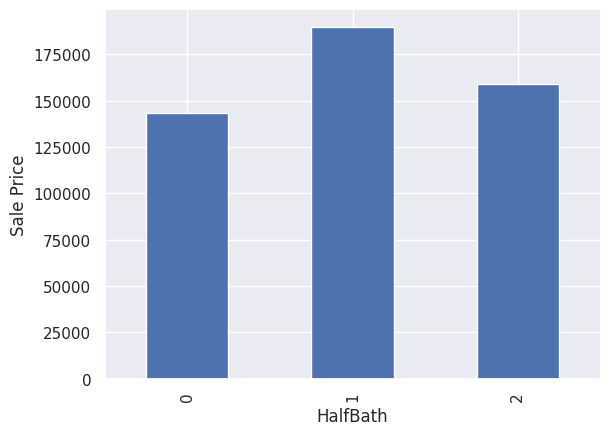

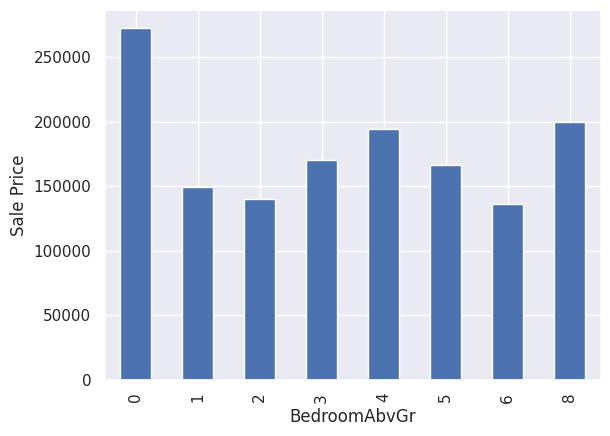

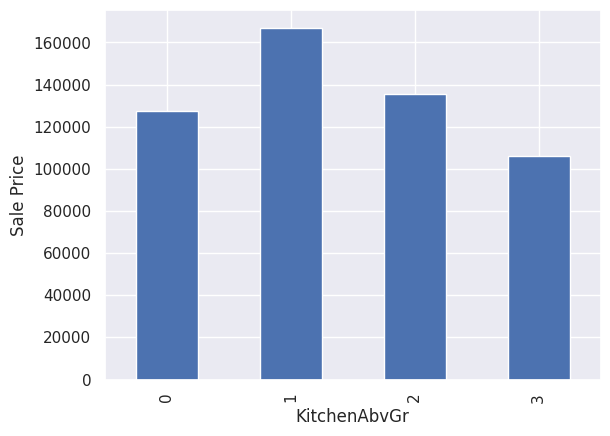

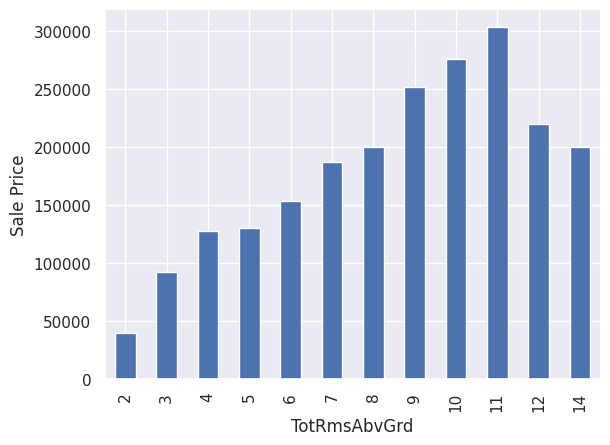

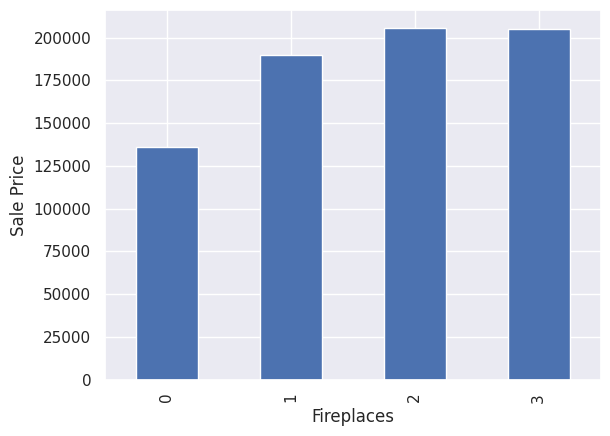

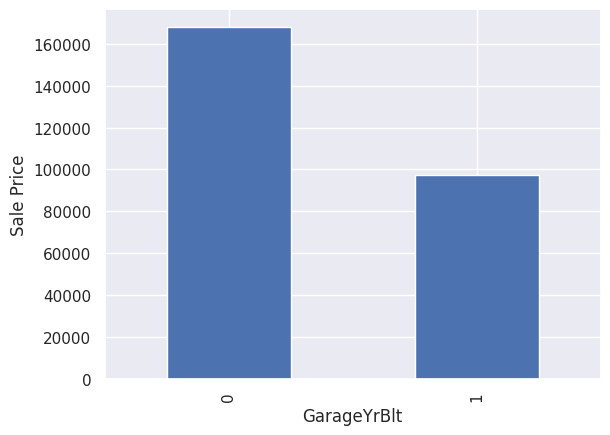

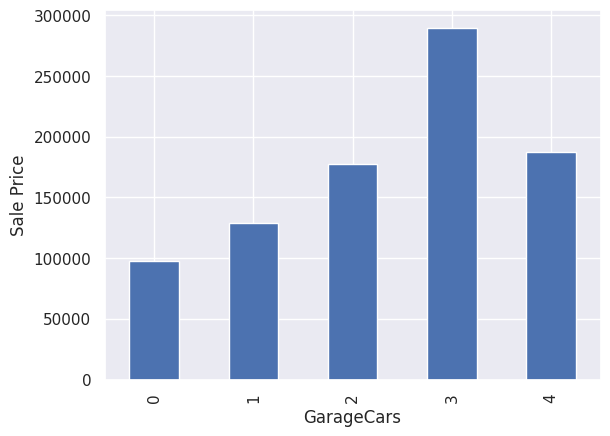

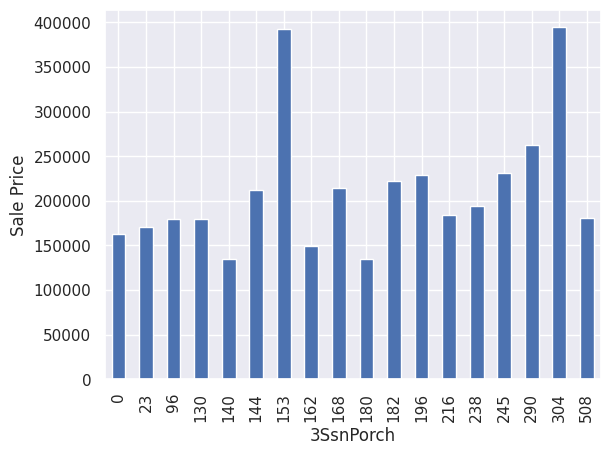

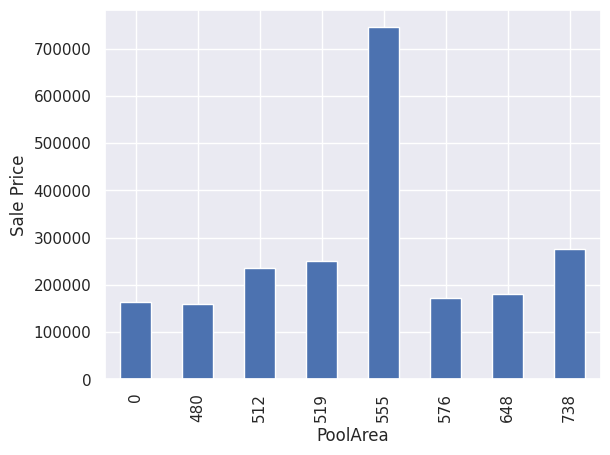

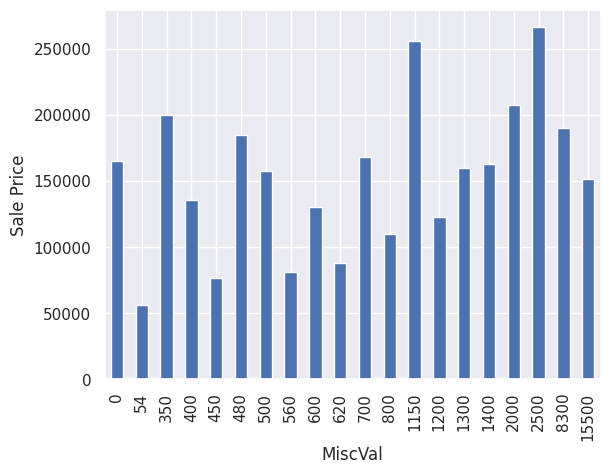

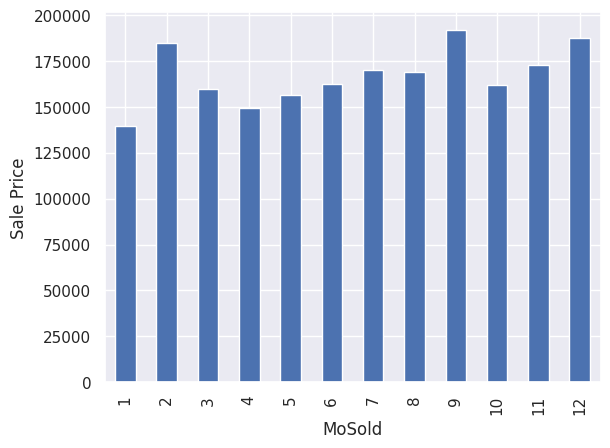

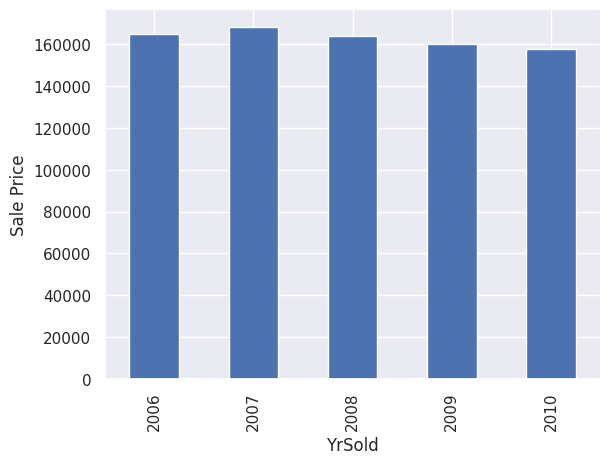

In [ ]:
for i in discrete:
  copied_data.groupby(i)["SalePrice"].median().plot.bar()
  plt.xlabel(i)
  plt.ylabel("Sale Price")
  plt.show()


# Continuous Variable

In [ ]:
continuous = [i for i in numericalData_columns if i not in discrete+temporal]
continuous

['LotArea',
 'BsmtFinSF1',
 'BsmtFinSF2',
 'BsmtUnfSF',
 'TotalBsmtSF',
 '1stFlrSF',
 '2ndFlrSF',
 'GrLivArea',
 'GarageArea',
 'WoodDeckSF',
 'OpenPorchSF',
 'EnclosedPorch',
 'ScreenPorch',
 'SalePrice']

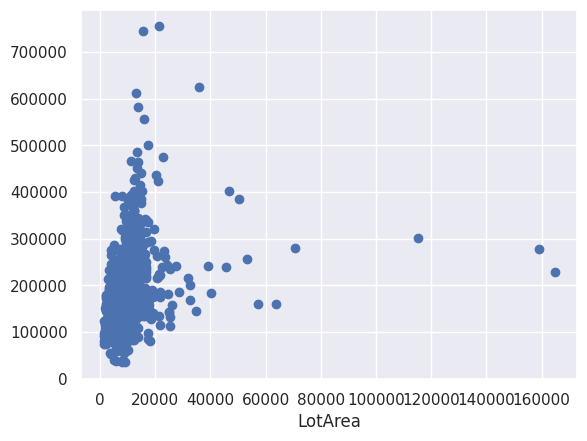

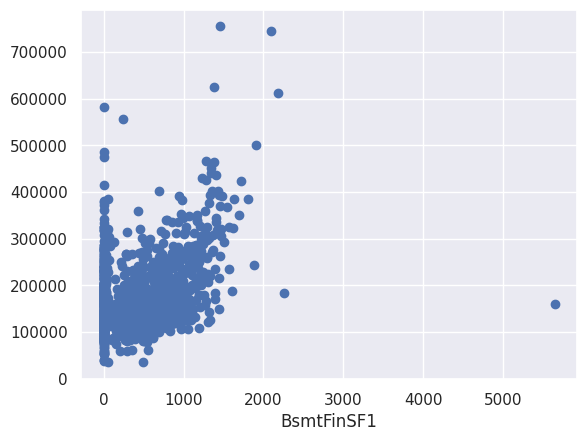

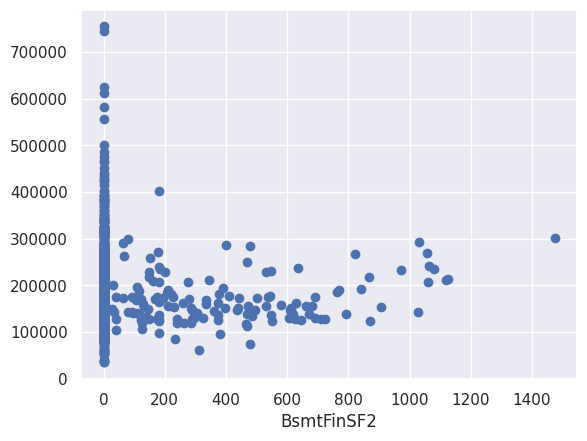

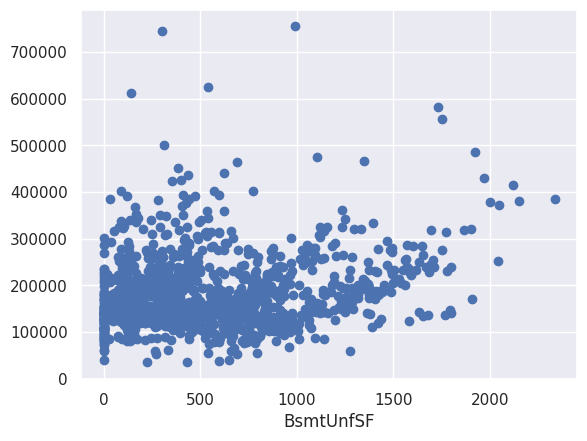

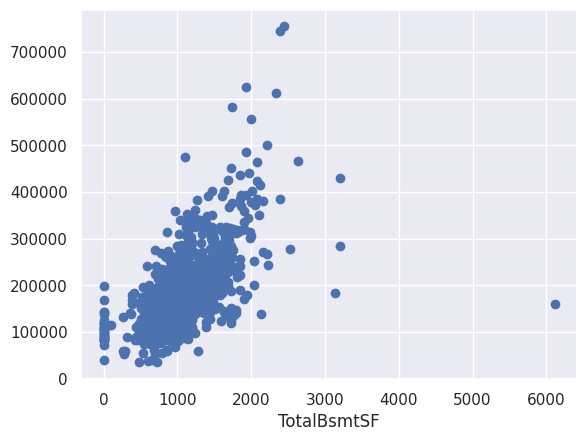

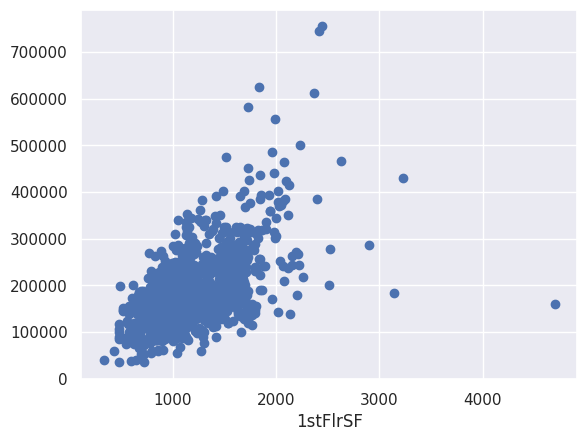

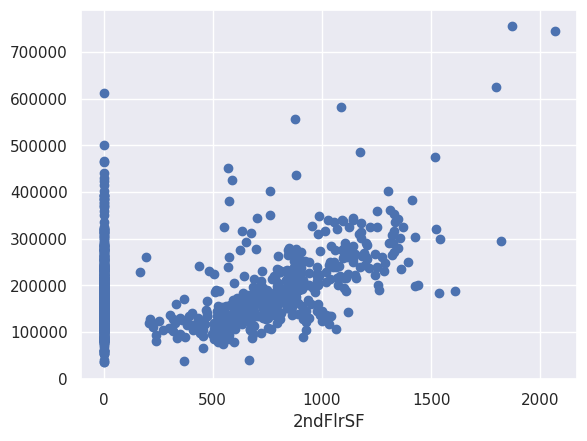

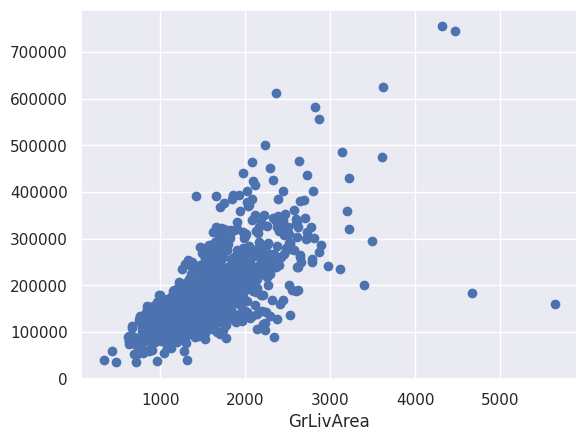

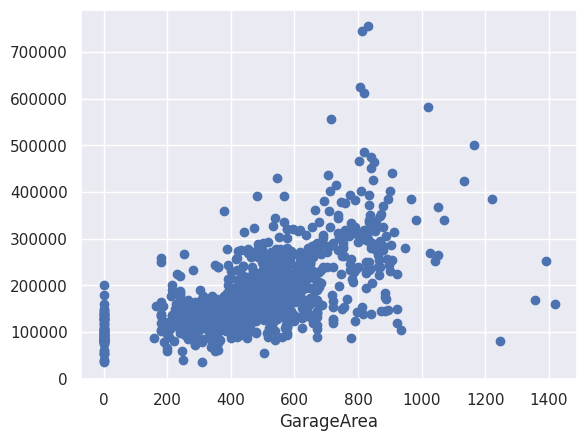

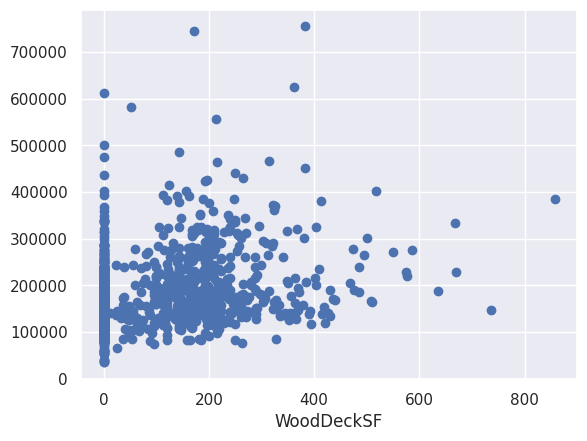

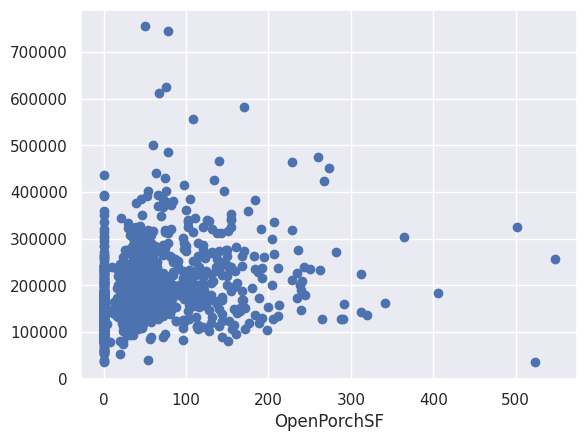

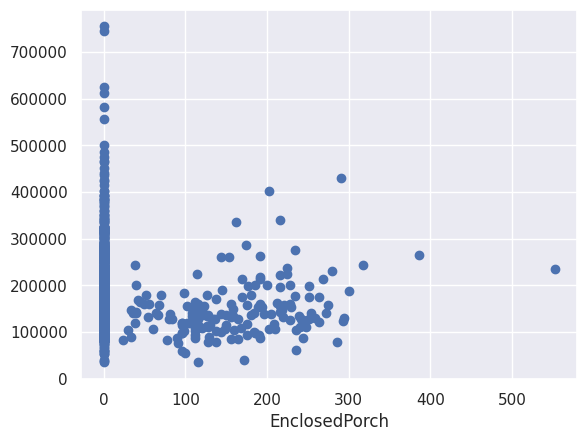

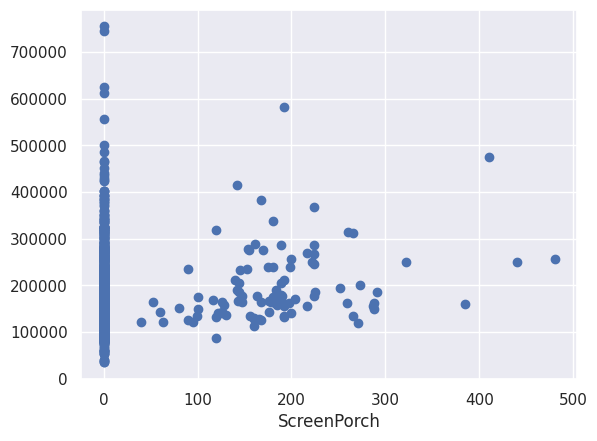

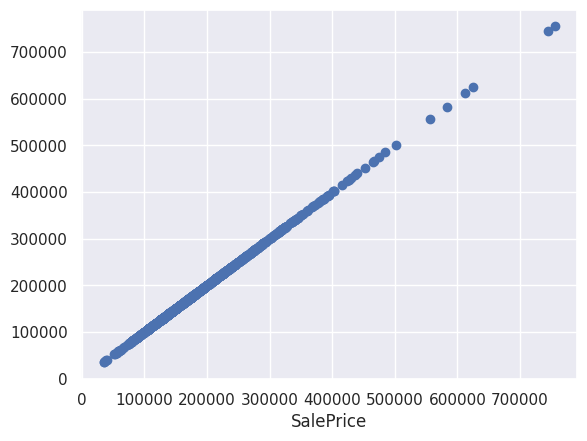

In [ ]:
for i in continuous:
  plt.scatter(copied_data[i],copied_data["SalePrice"])
  plt.xlabel(i)
  plt.show()

# Distribution of target feature

<Axes: xlabel='SalePrice', ylabel='Count'>

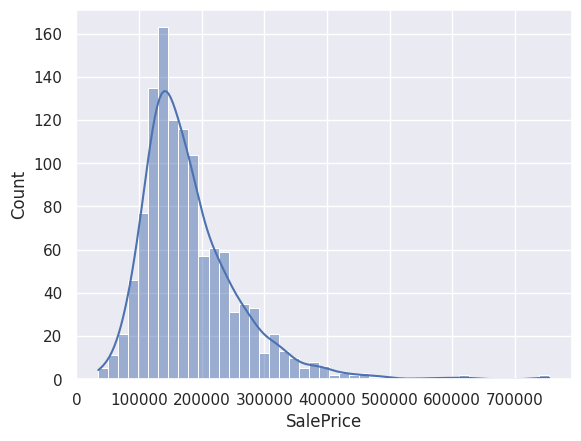

In [ ]:
sns.histplot(copied_data["SalePrice"], kde= True)

# Categorical Variable

In [ ]:
categoricalData_columns.columns

Index(['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'LotConfig',
       'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType',
       'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd',
       'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual',
       'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating',
       'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual', 'Functional',
       'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond',
       'PavedDrive', 'PoolQC', 'Fence', 'MiscFeature', 'SaleType',
       'SaleCondition'],
      dtype='object')

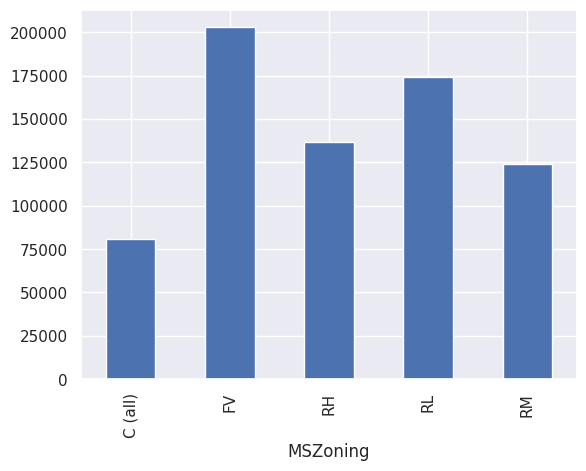

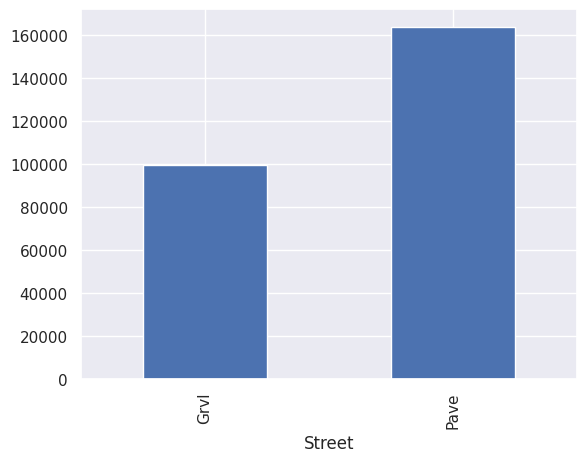

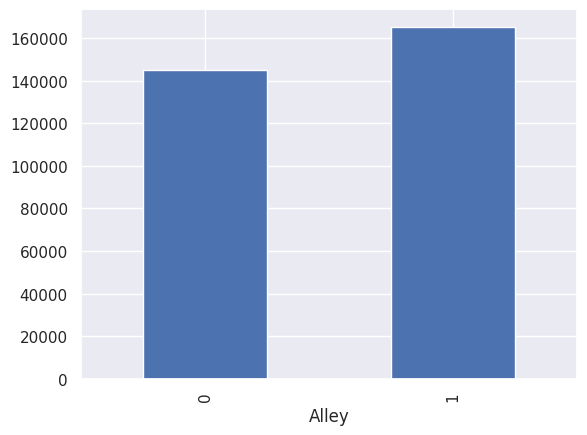

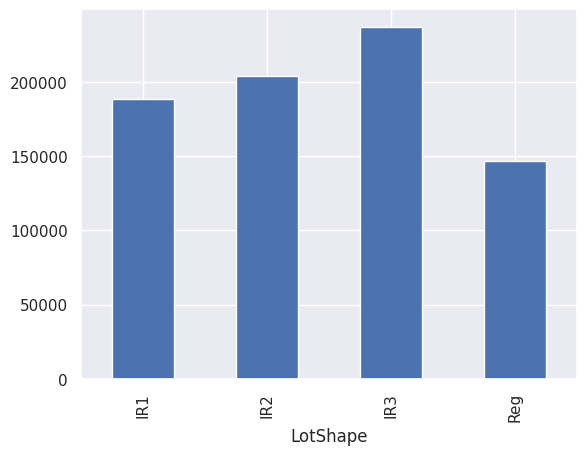

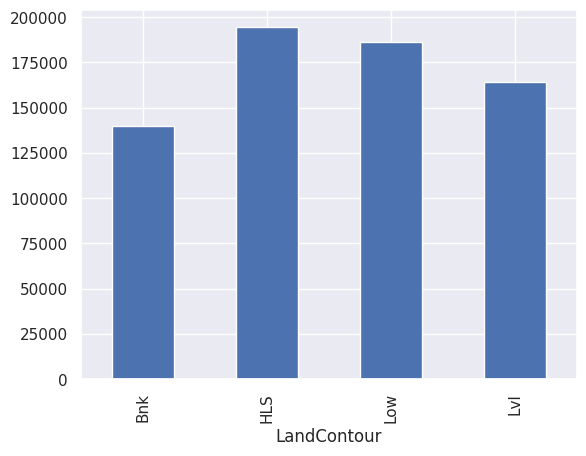

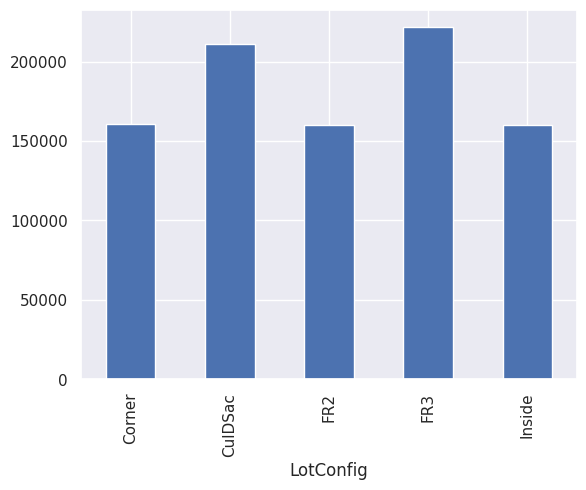

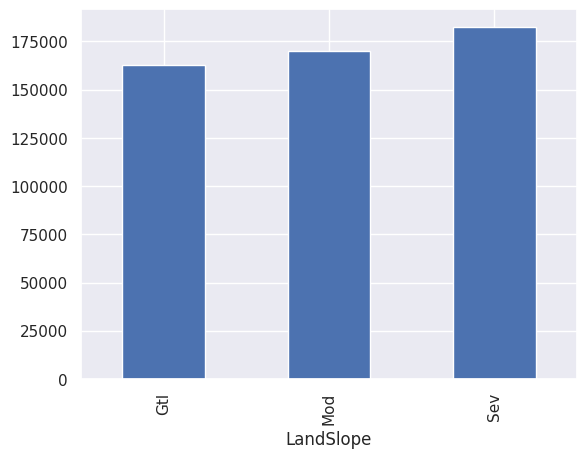

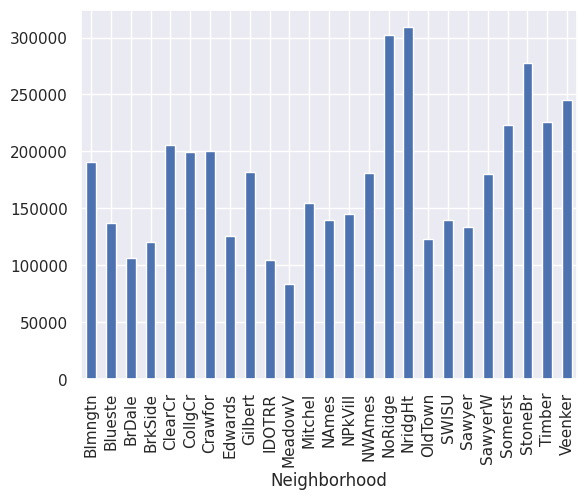

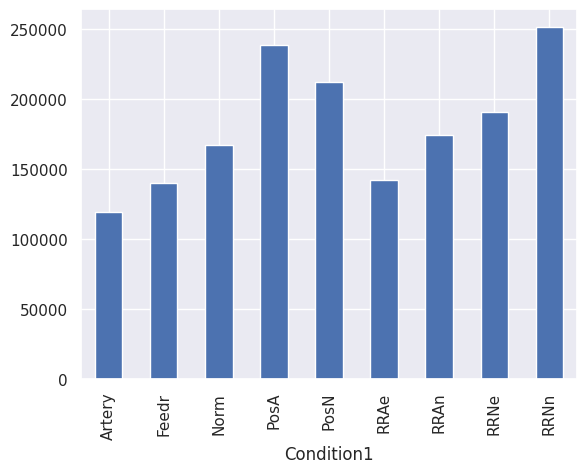

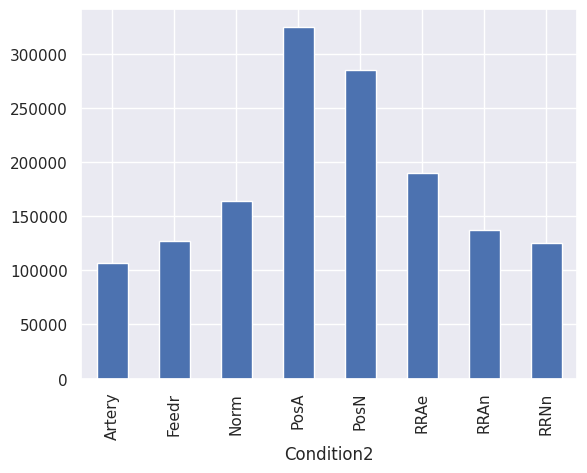

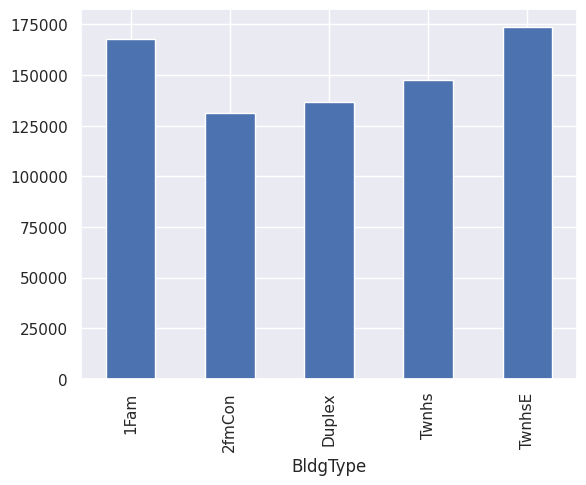

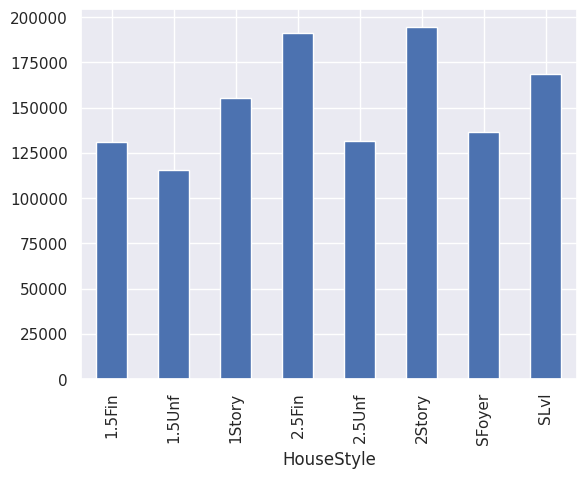

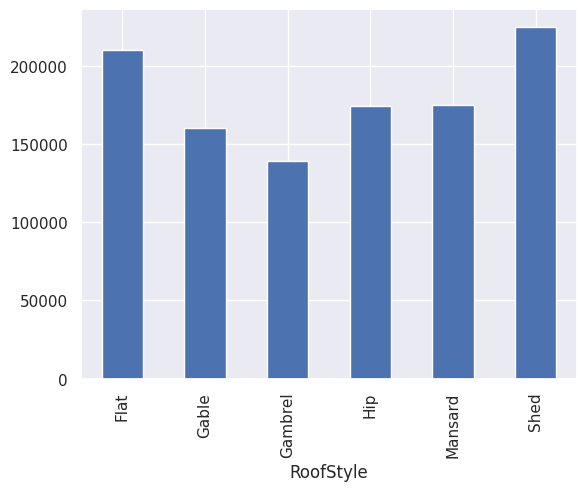

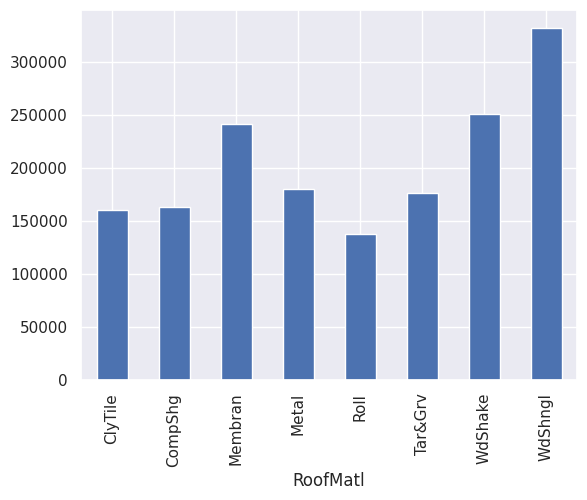

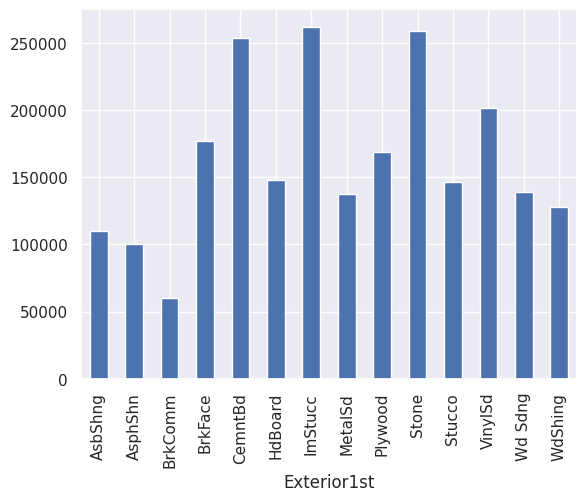

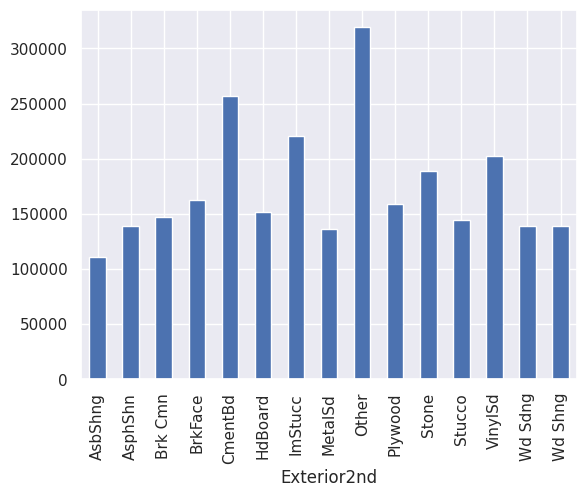

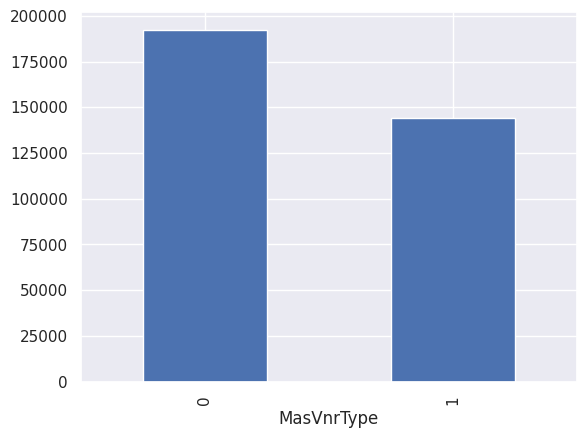

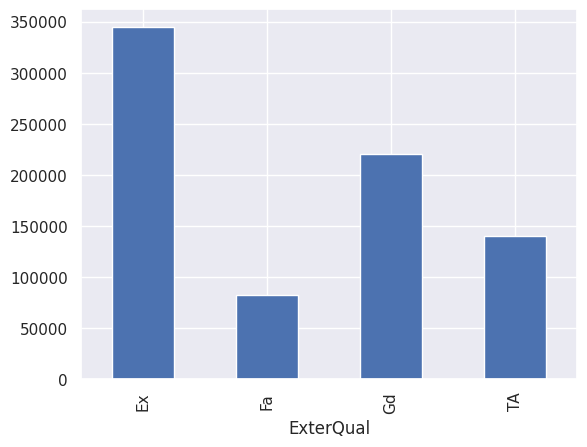

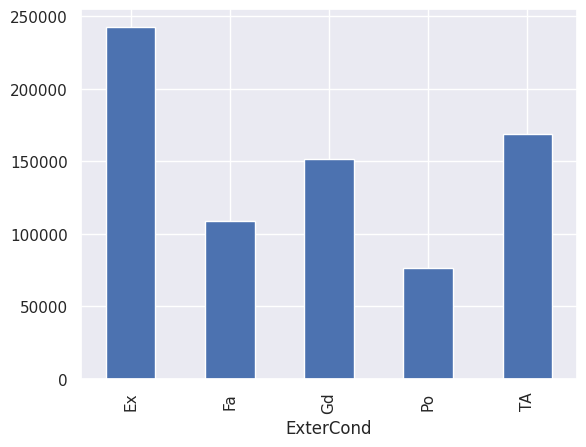

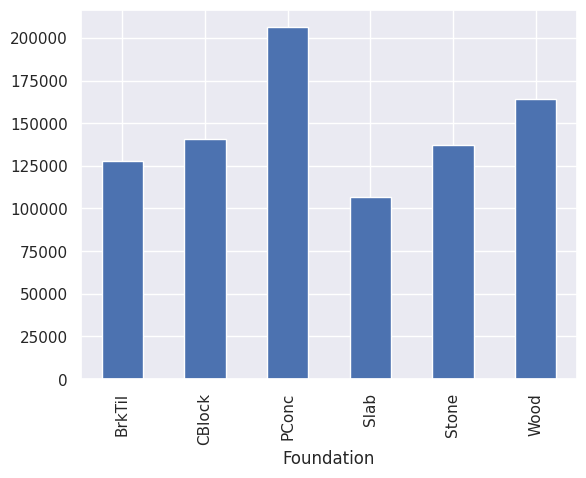

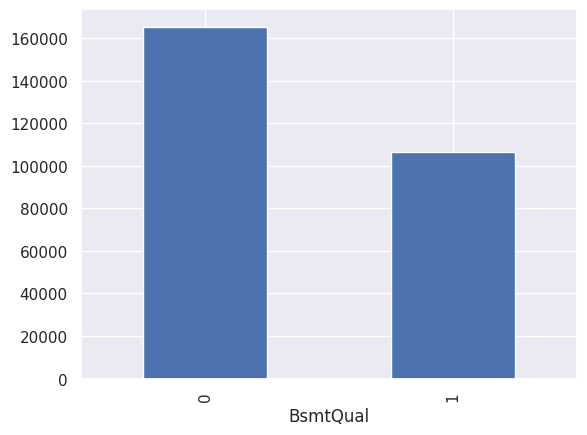

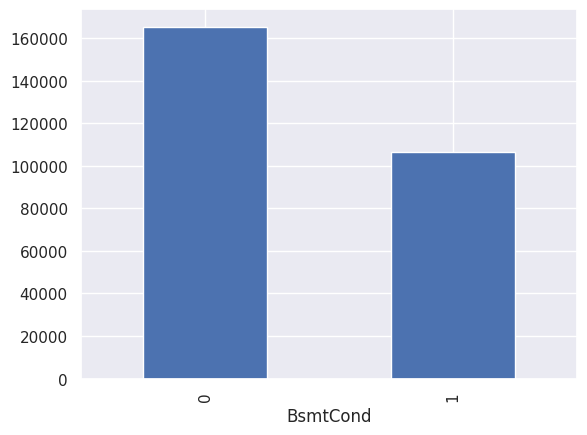

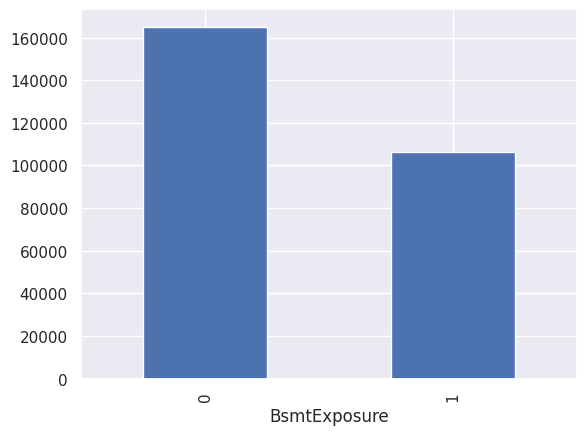

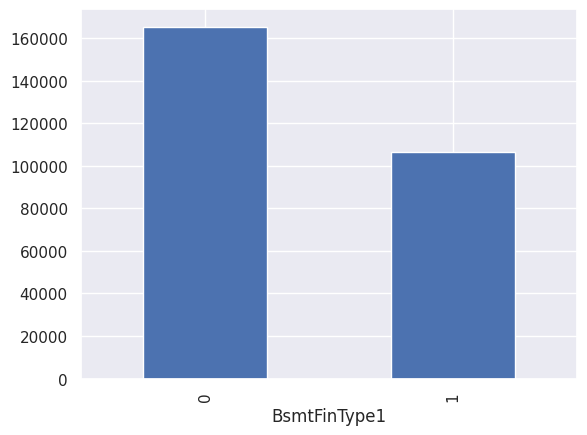

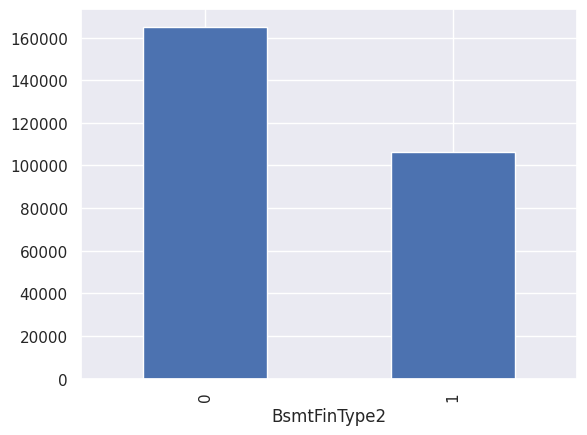

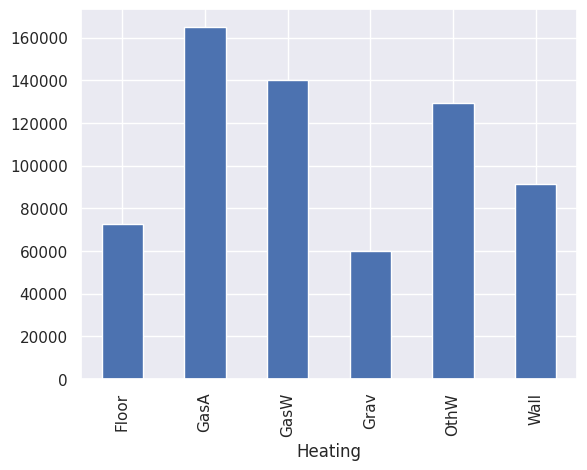

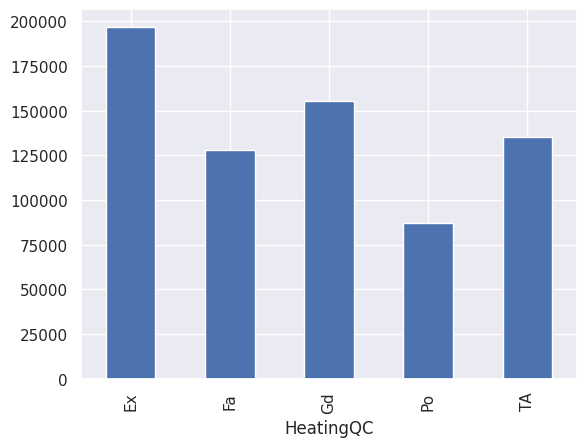

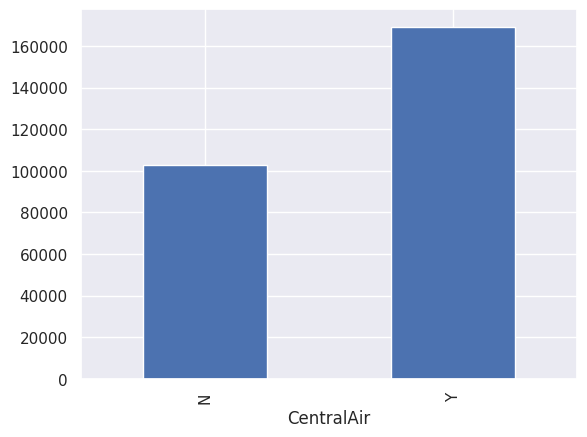

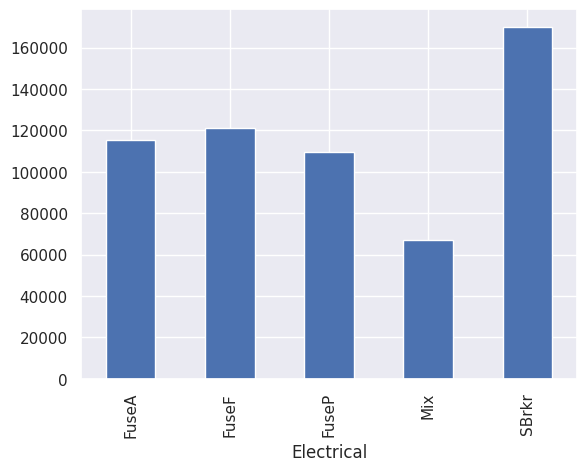

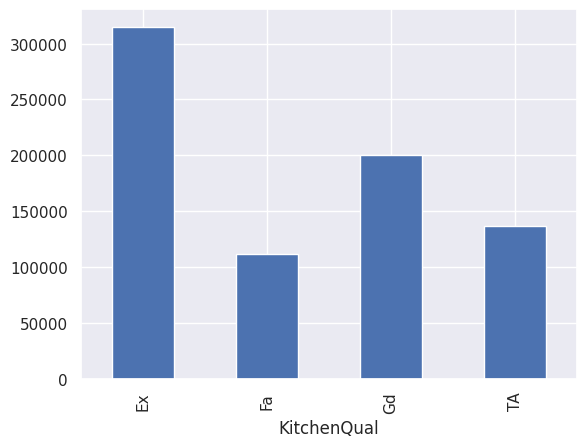

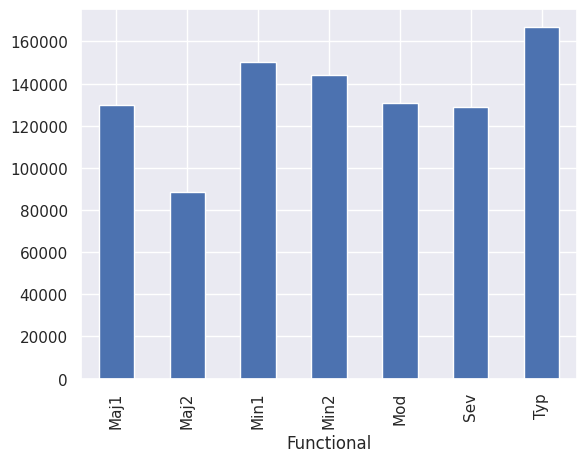

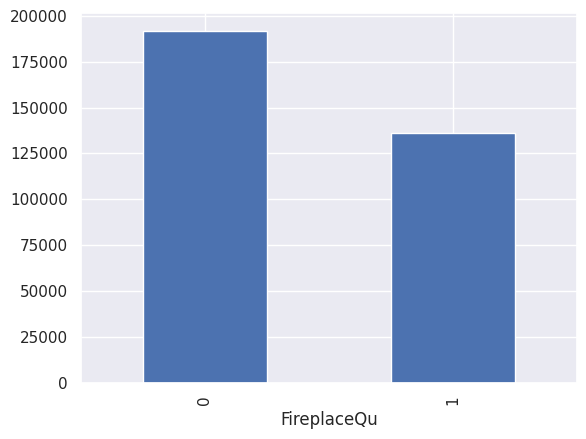

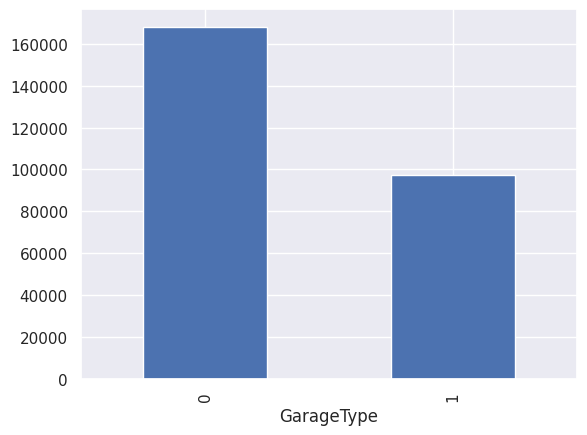

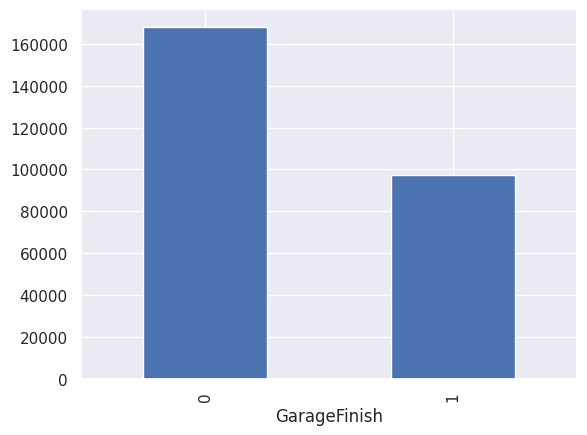

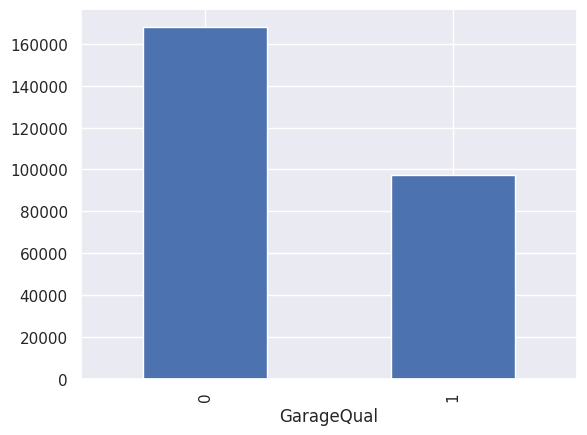

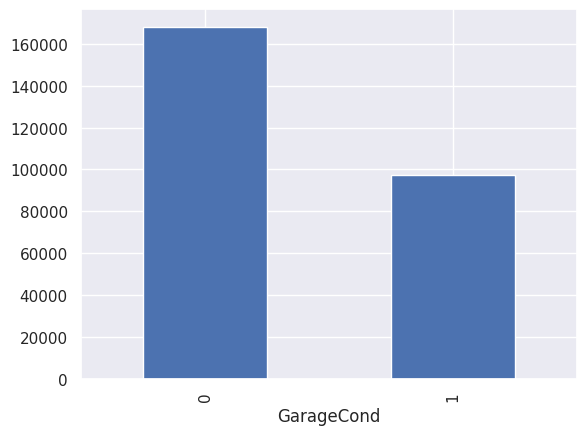

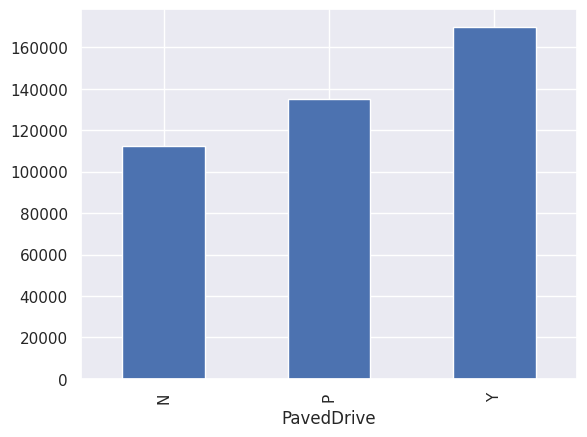

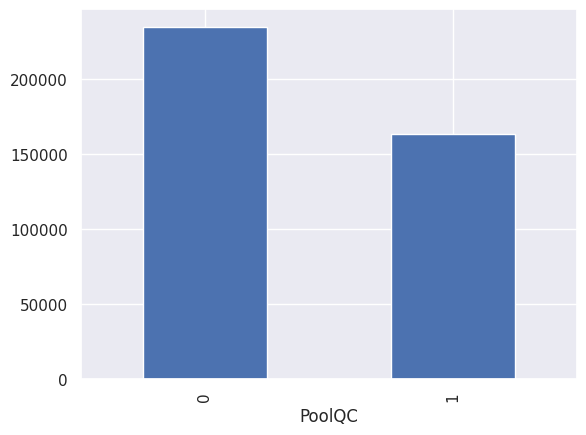

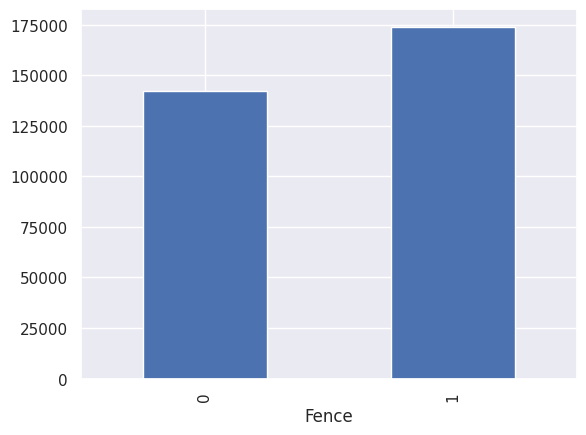

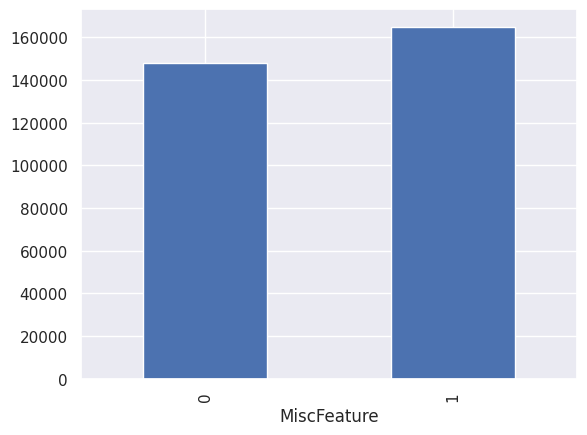

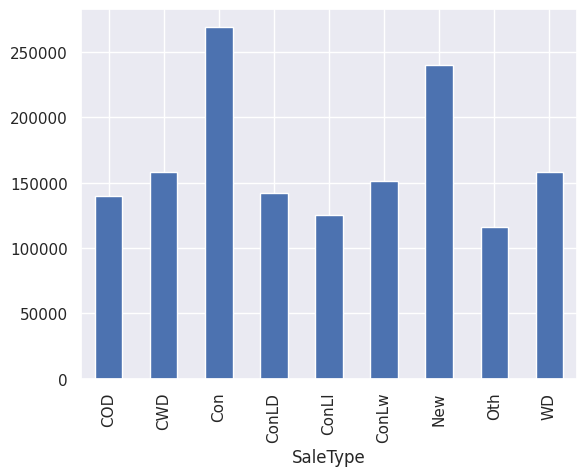

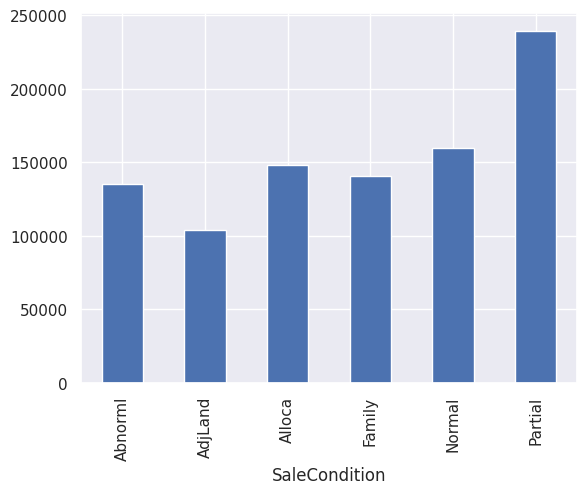

In [ ]:
for i in categoricalData_columns:
  copied_data.groupby(i)["SalePrice"].median().plot.bar()
  plt.show()

In [ ]:
train_data.shape

(1168, 79)

# Correlation Analysis

<Axes: >

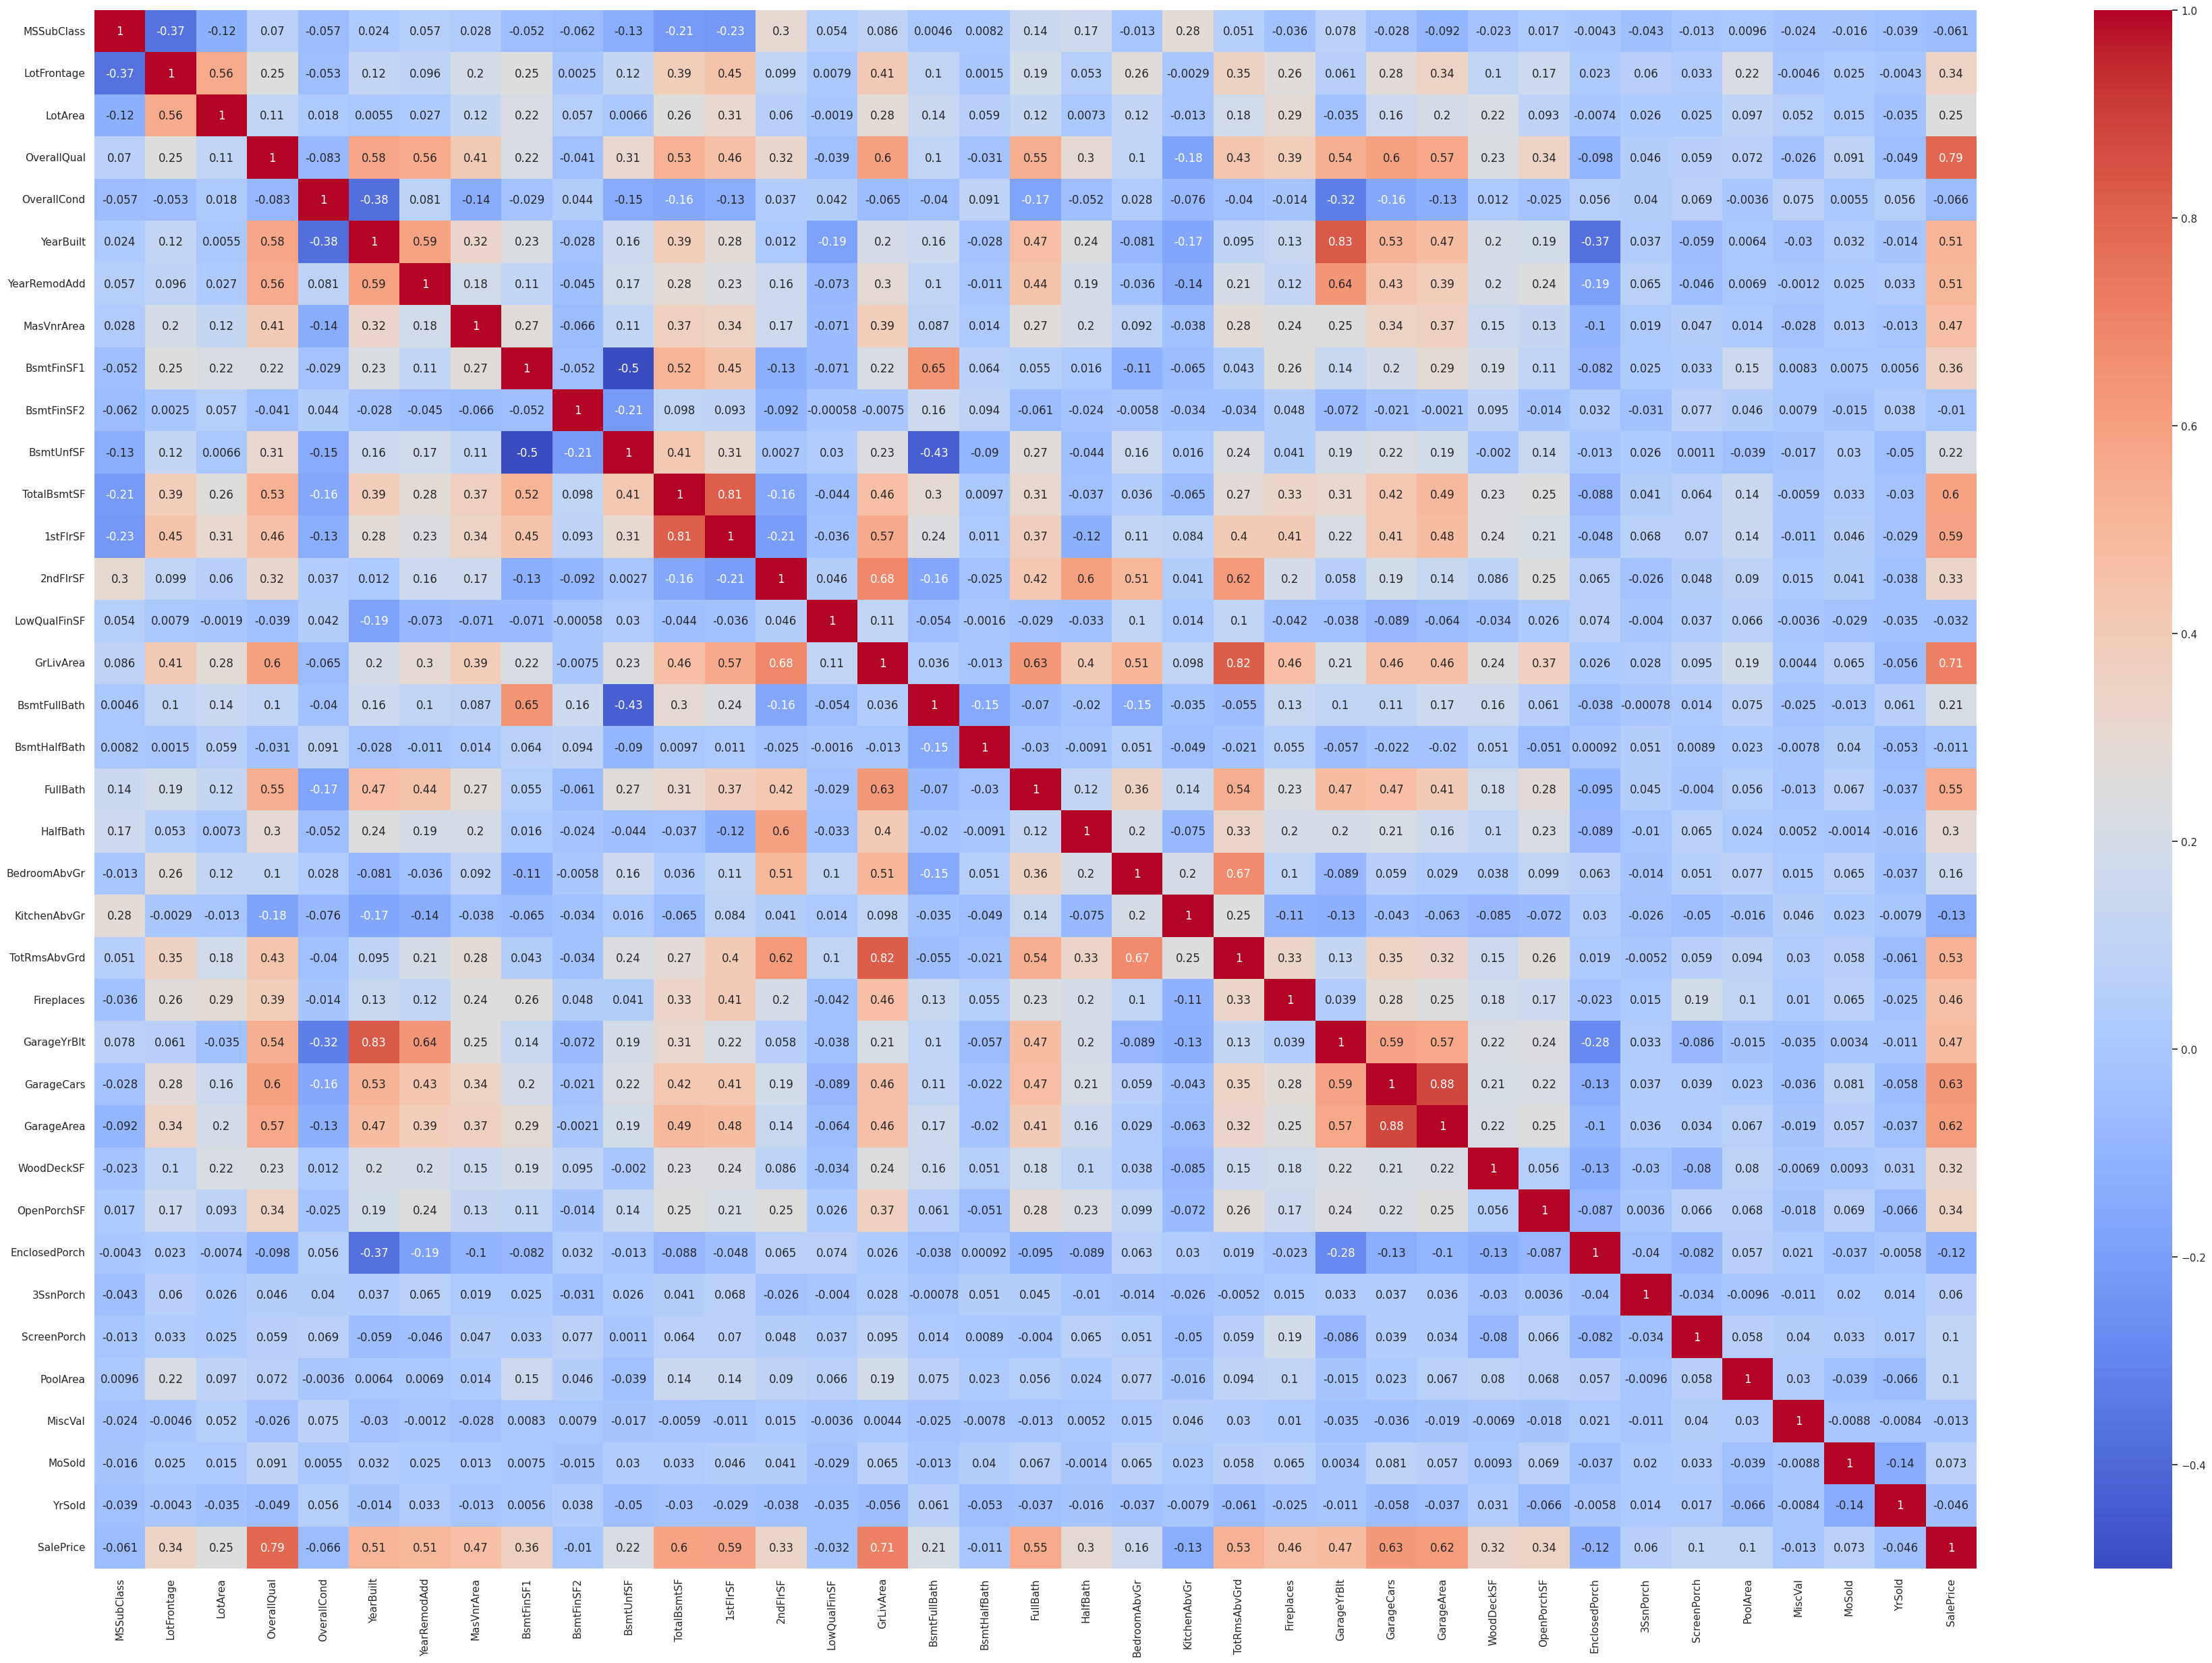

In [ ]:
plt.figure(figsize=(45,30))
sns.heatmap(numericalData_columns.corr(), annot = True, cmap="coolwarm")

# Univariate Analysis

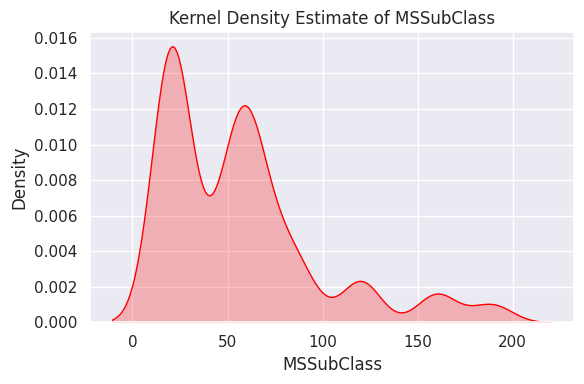

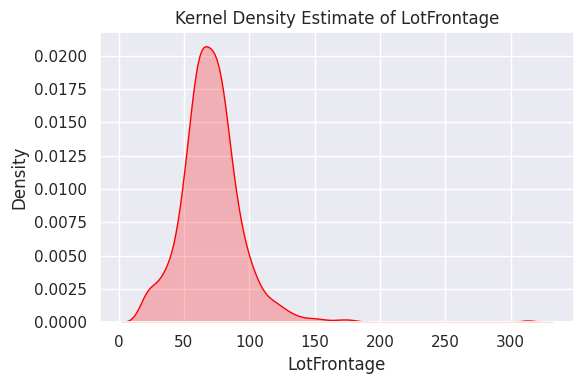

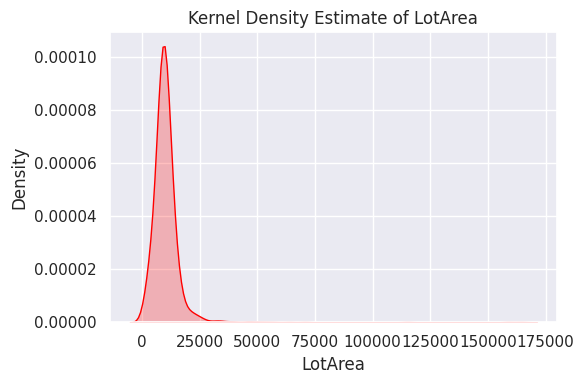

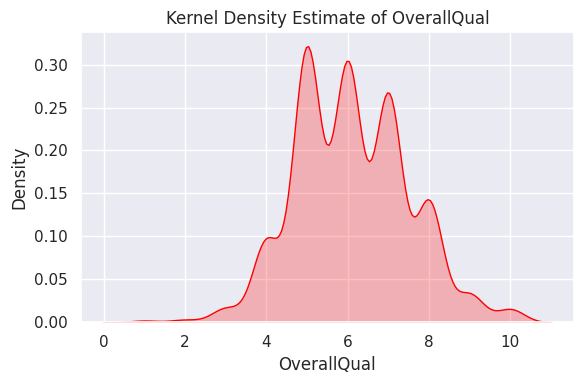

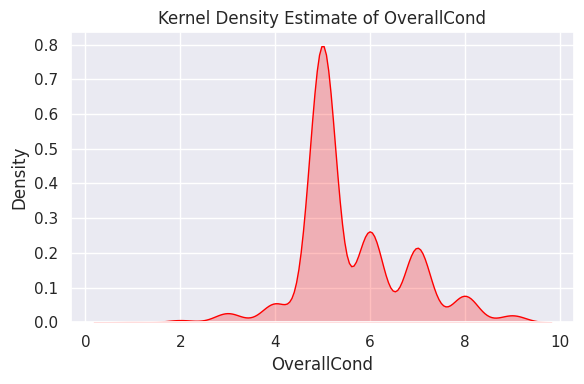

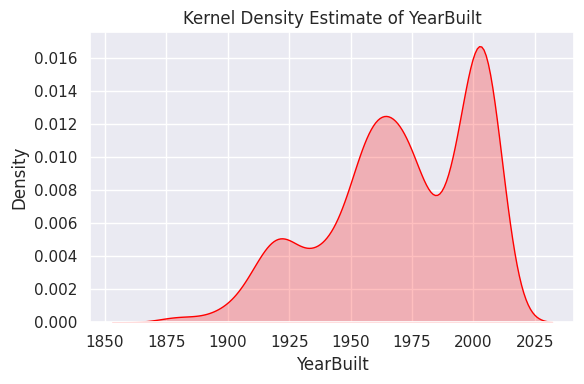

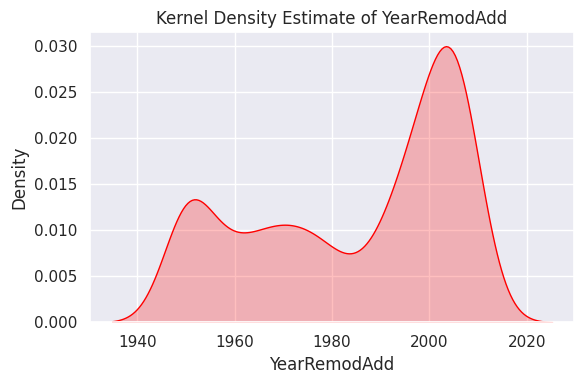

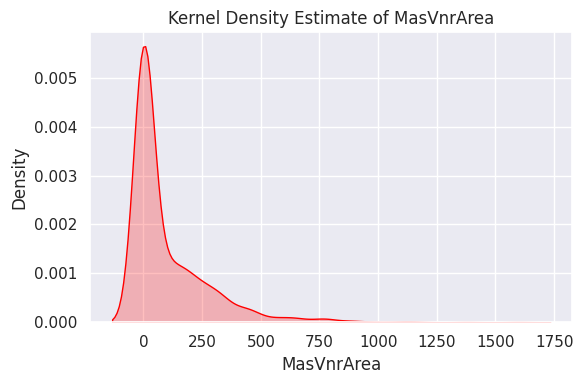

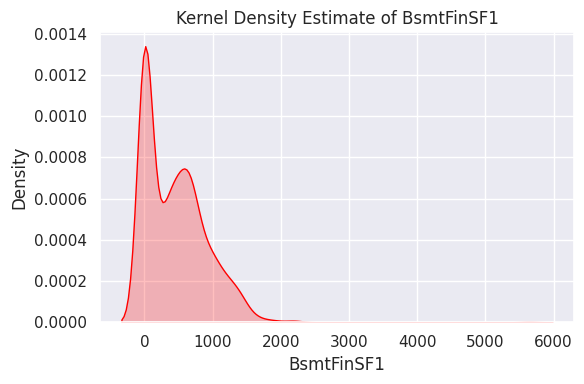

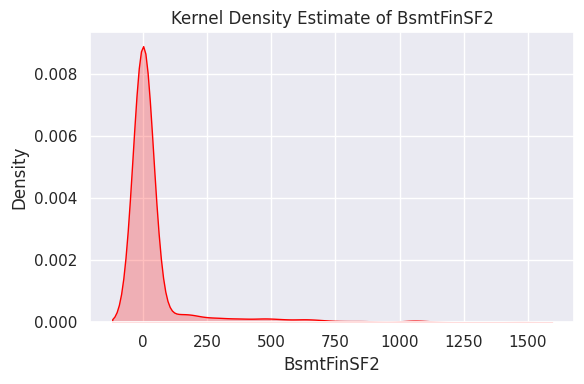

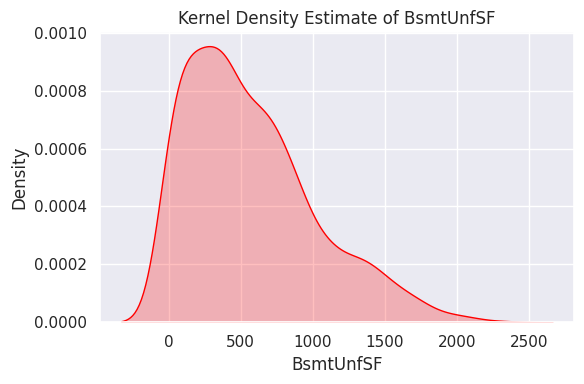

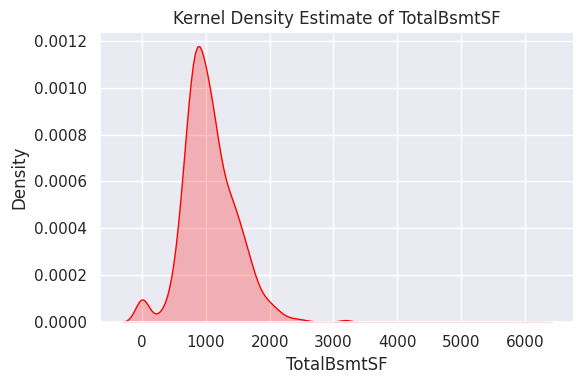

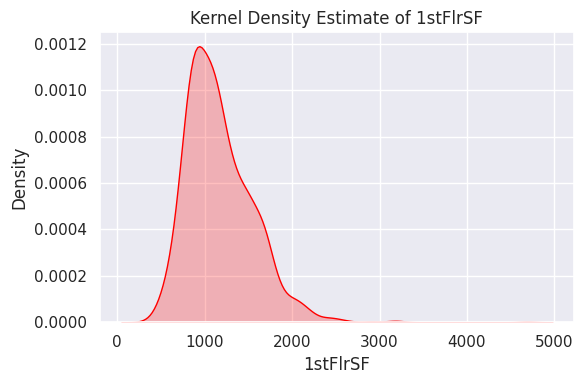

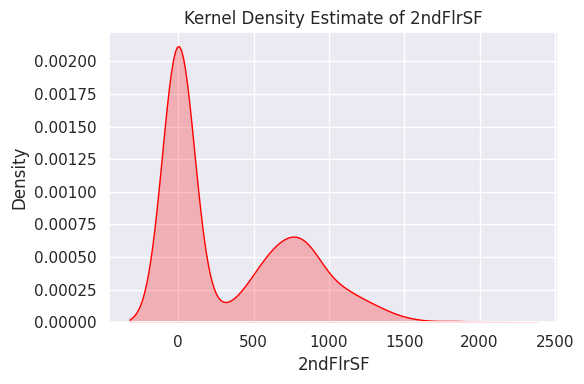

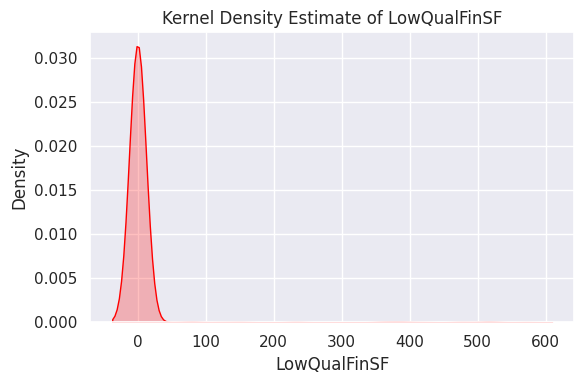

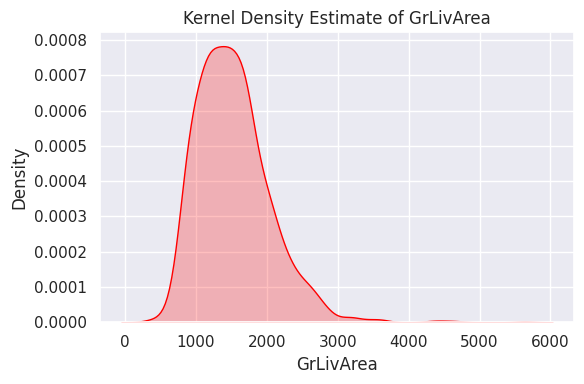

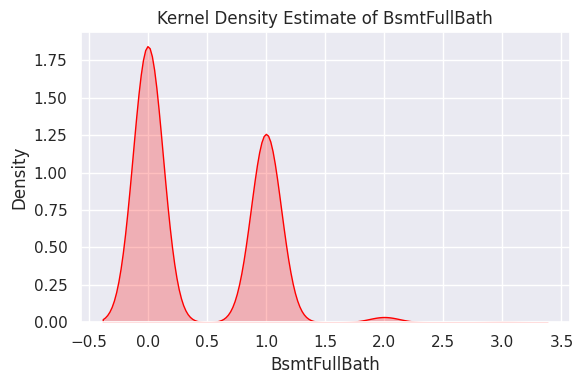

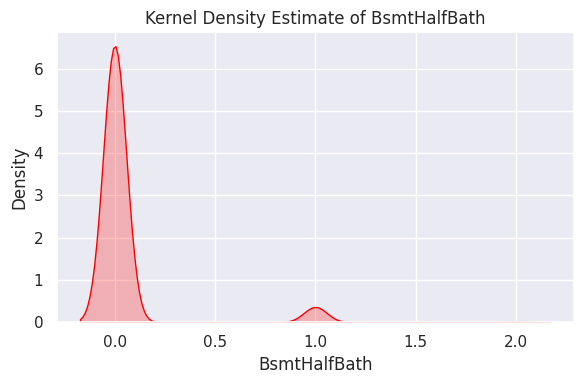

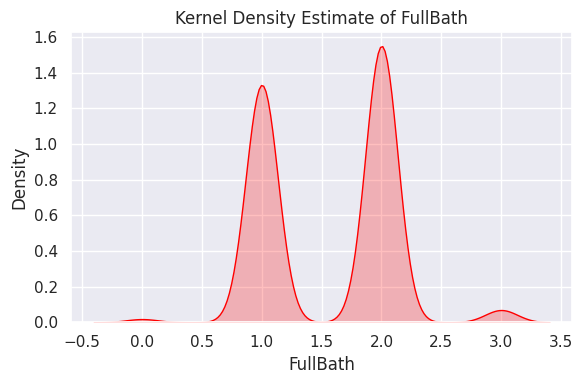

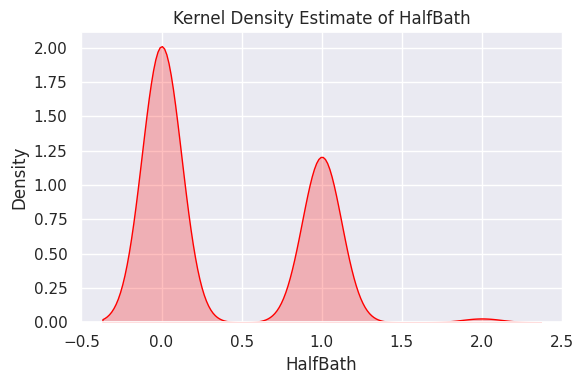

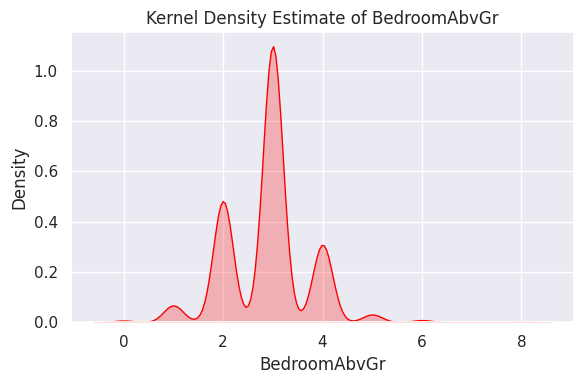

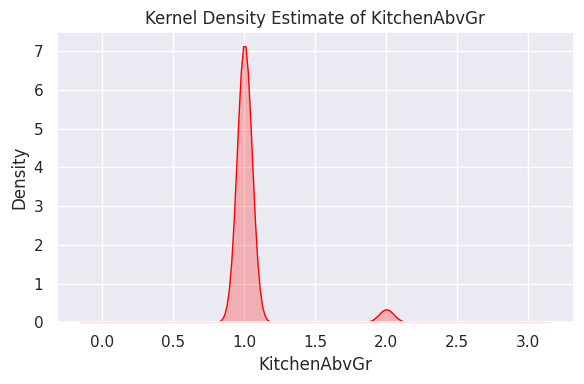

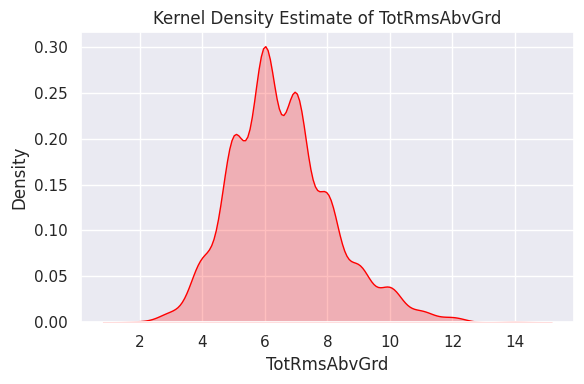

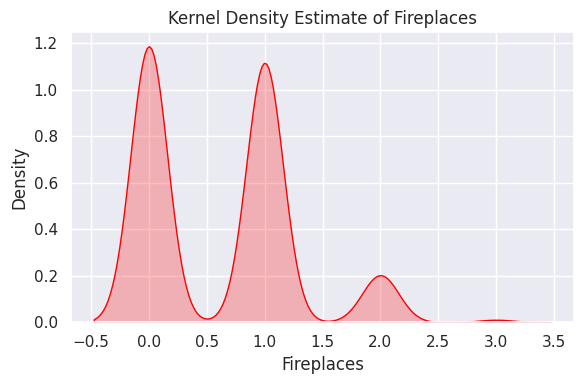

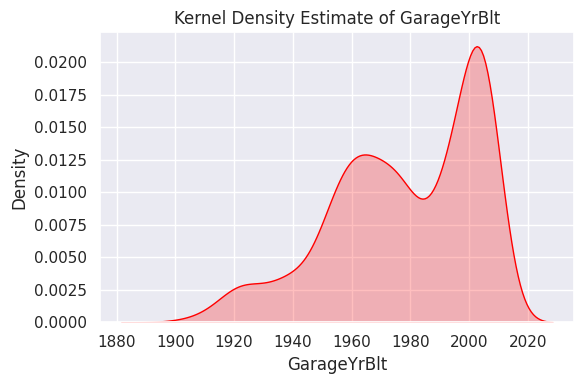

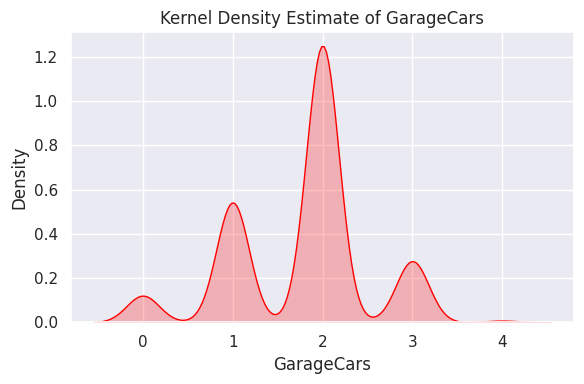

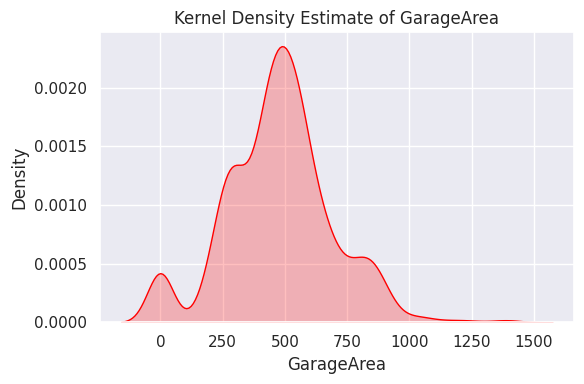

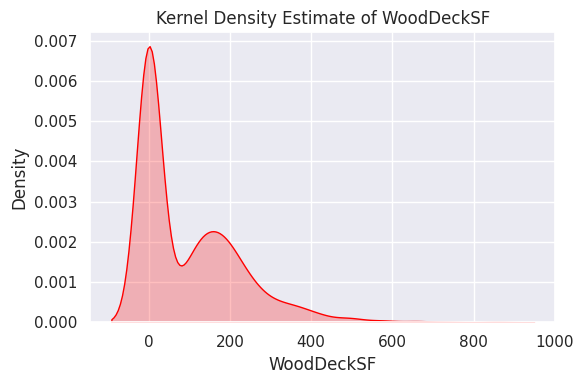

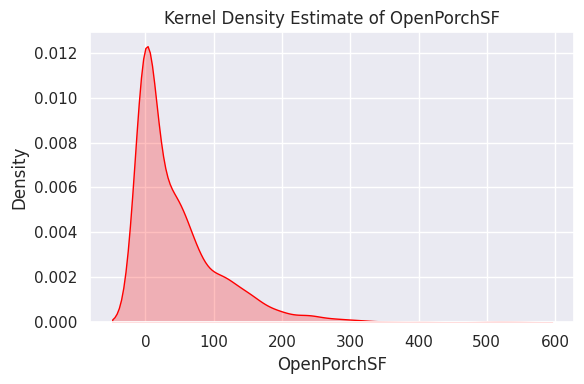

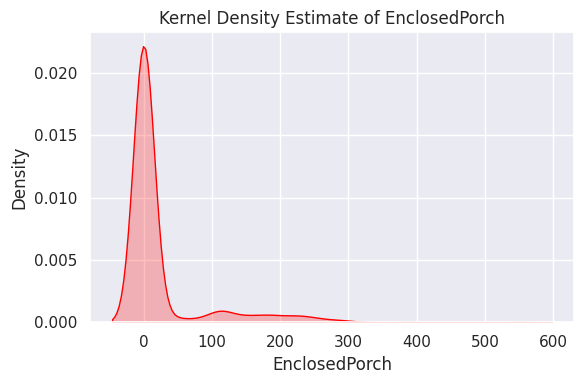

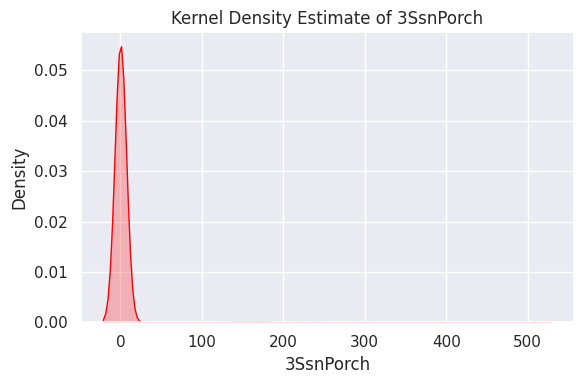

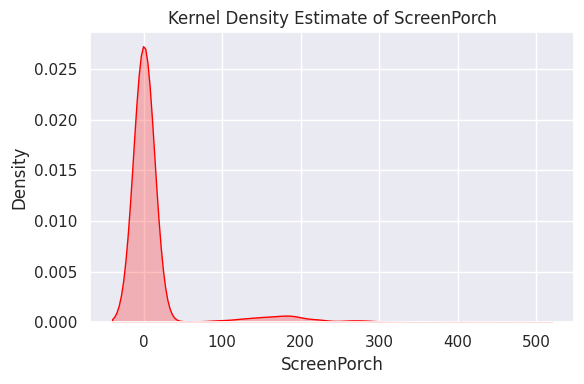

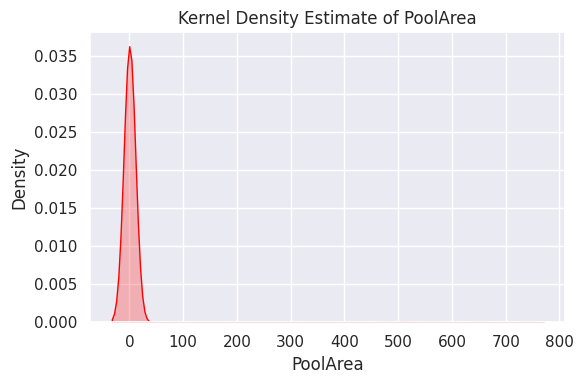

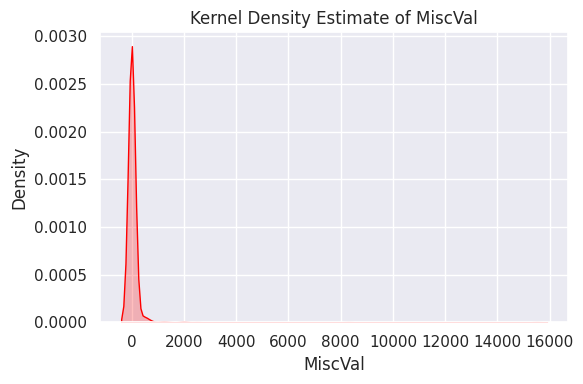

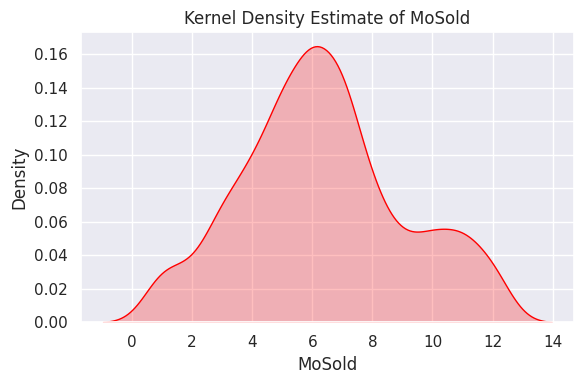

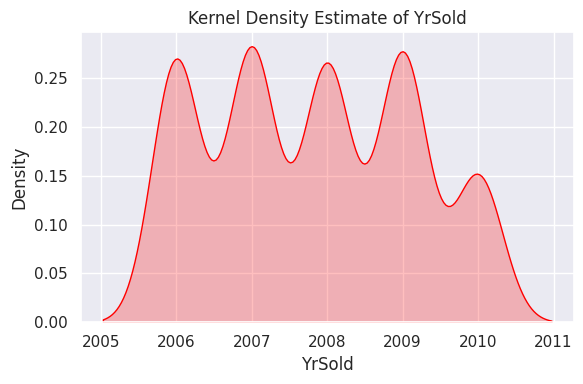

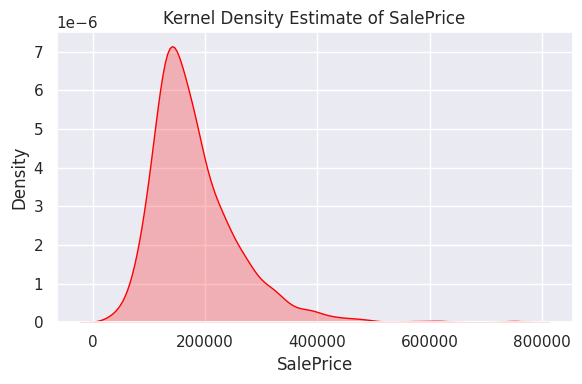

In [ ]:
for i in numericalData_columns:
    plt.figure(figsize=(6, 4))  # Adjust the figure size
    sns.kdeplot(train_data[i], color="red", fill=True)  # Use KDE plot
    plt.title(f"Kernel Density Estimate of {i}")
    plt.xlabel(f"{i}")
    plt.ylabel("Density")
    plt.tight_layout()
    plt.show()


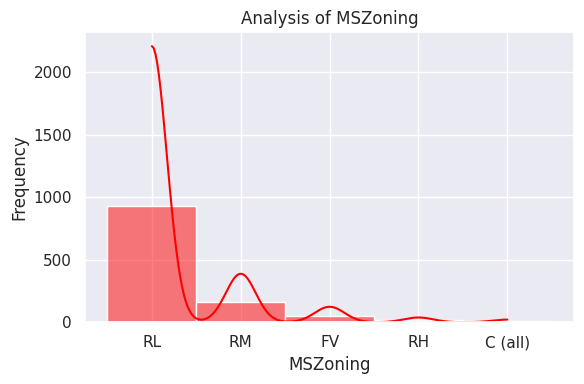

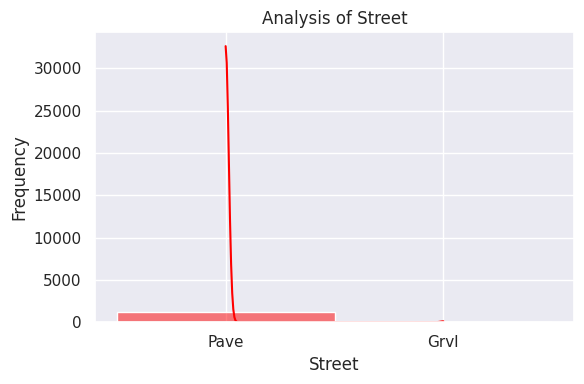

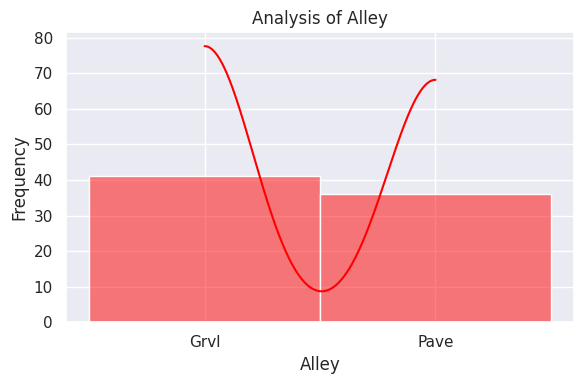

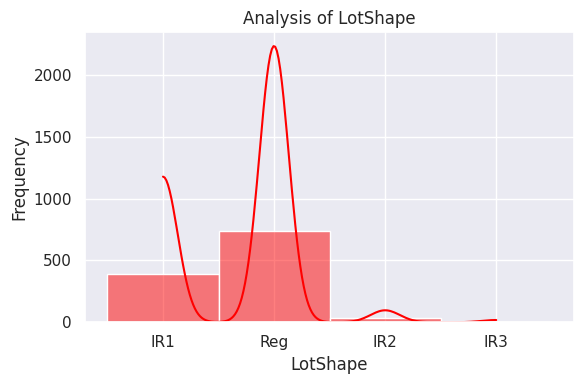

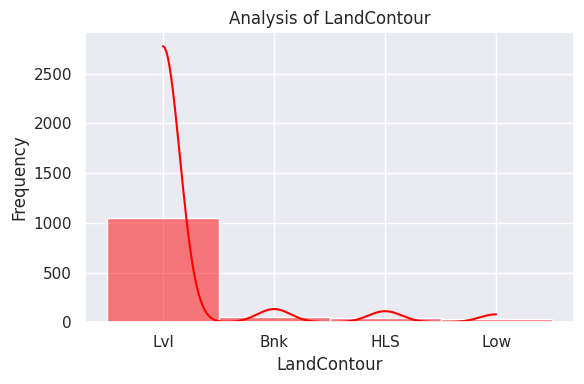

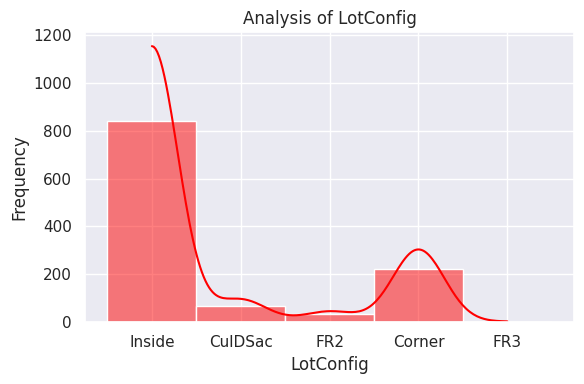

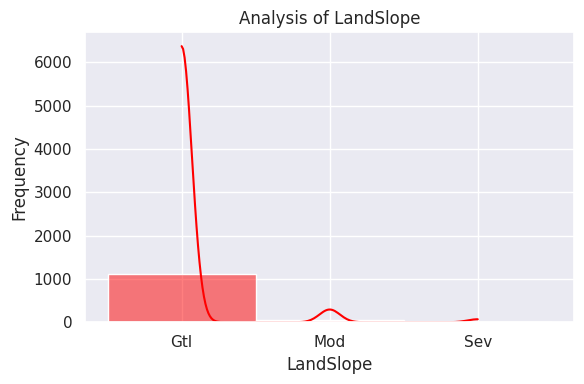

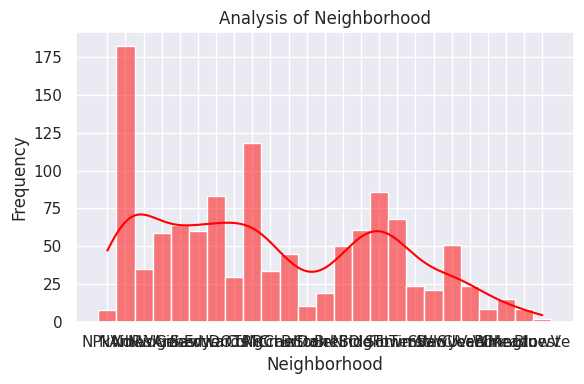

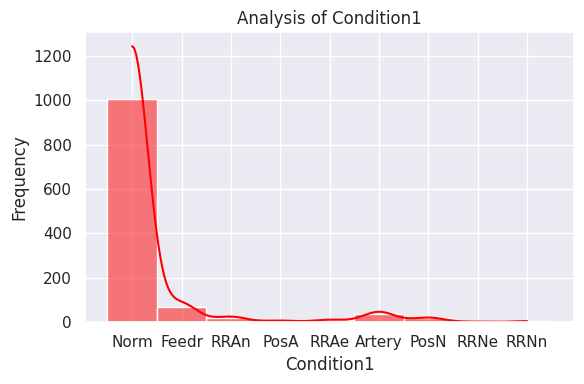

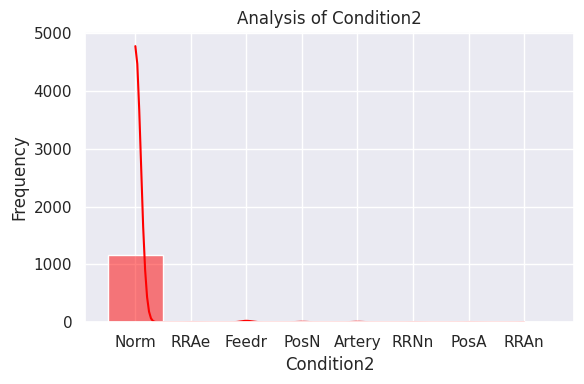

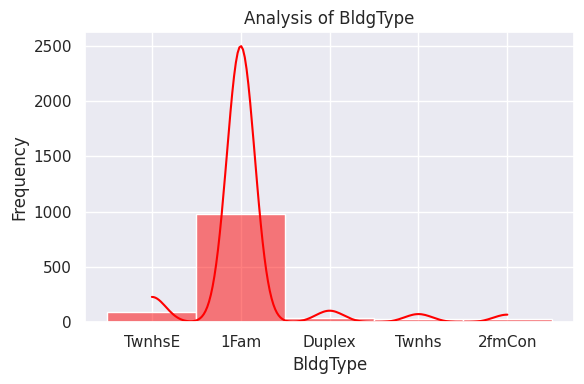

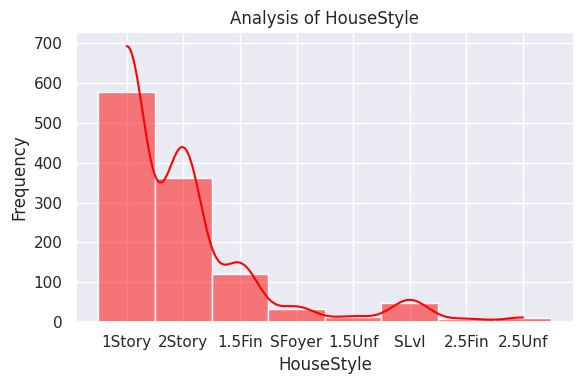

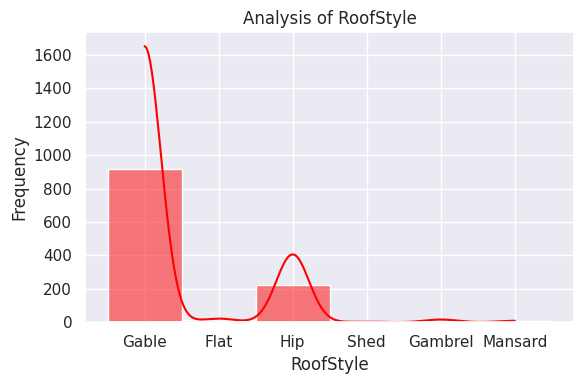

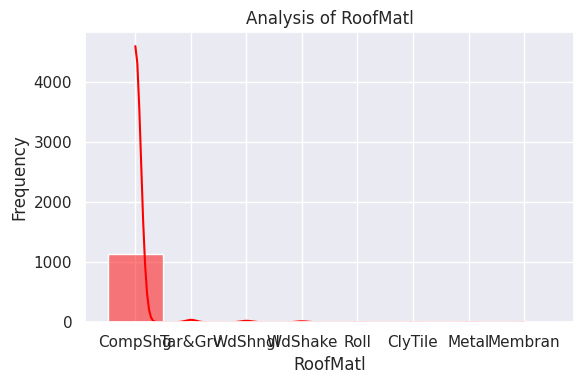

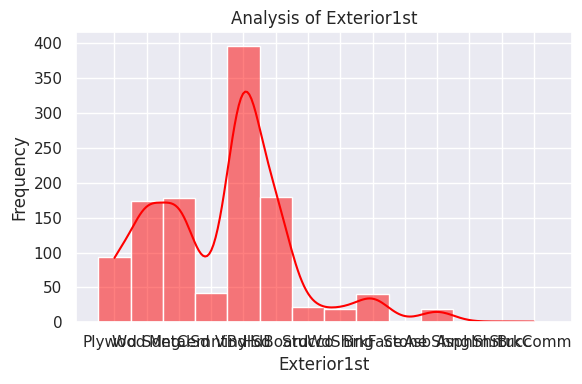

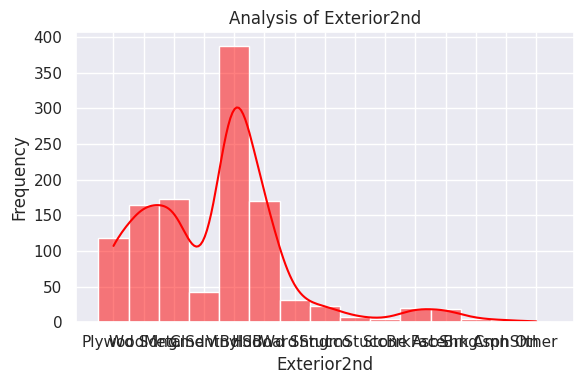

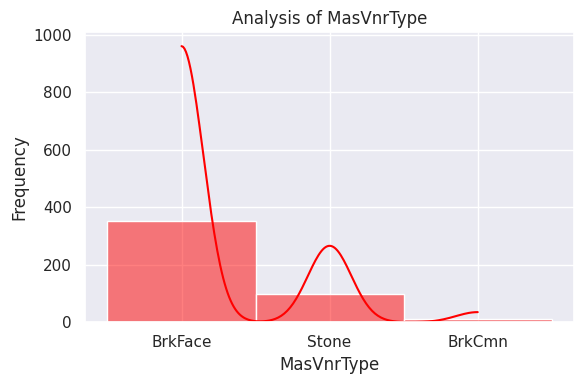

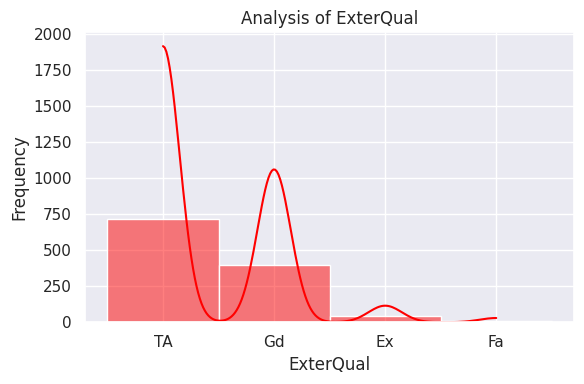

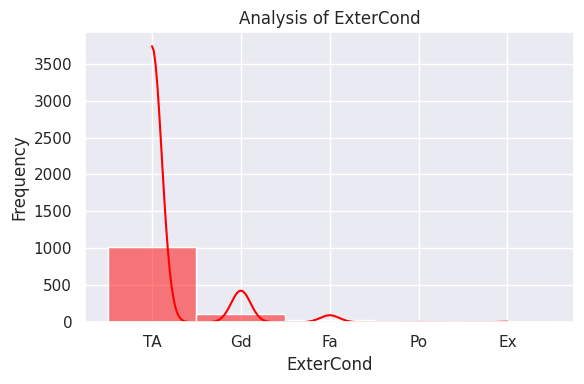

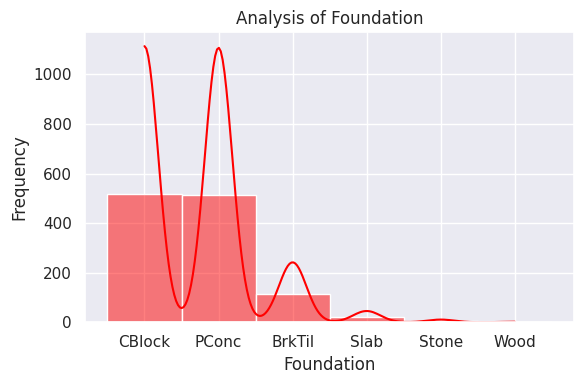

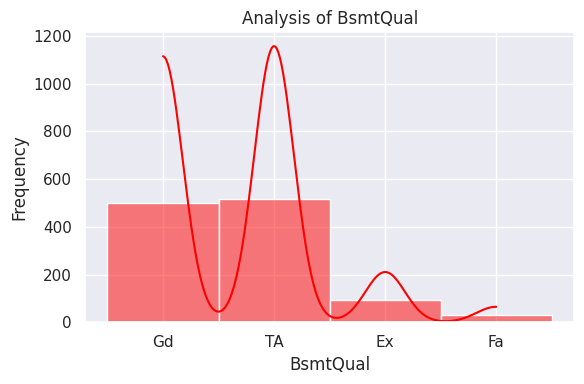

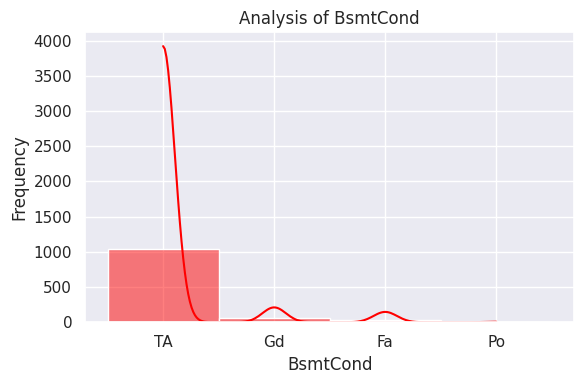

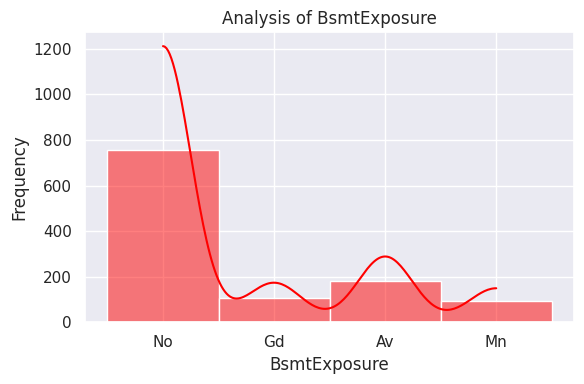

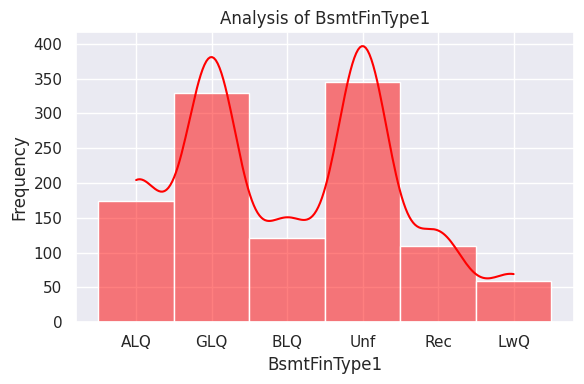

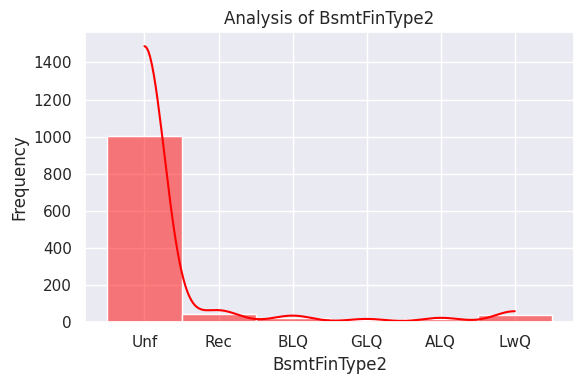

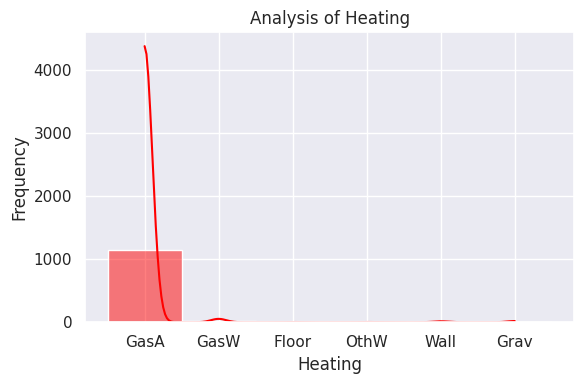

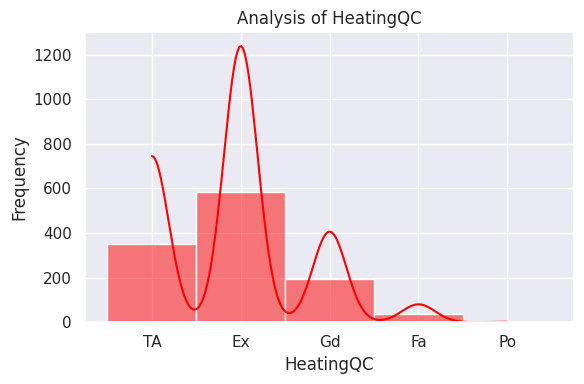

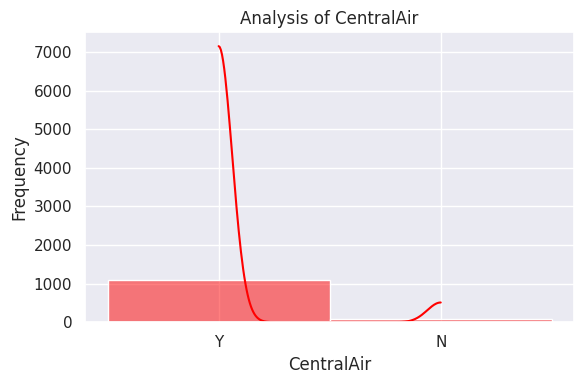

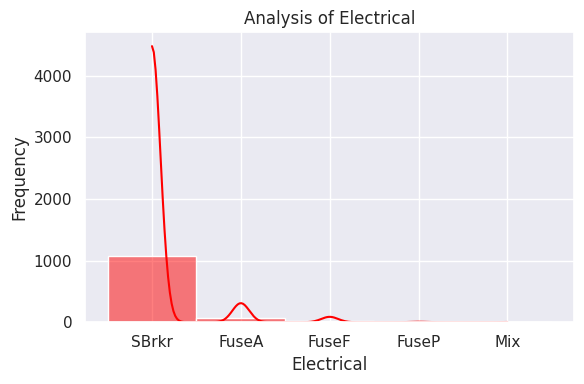

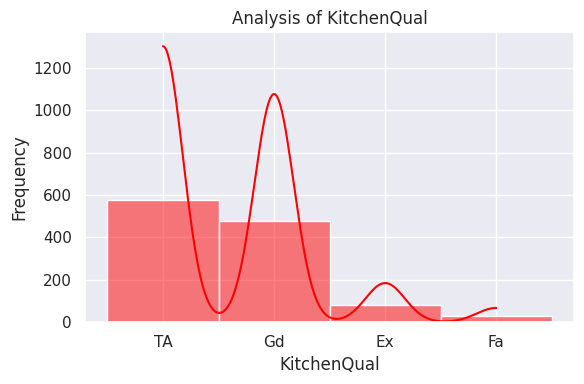

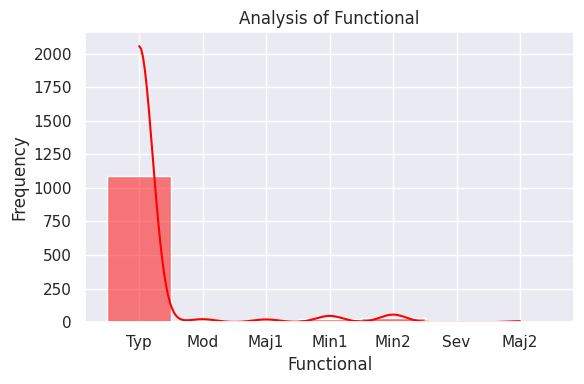

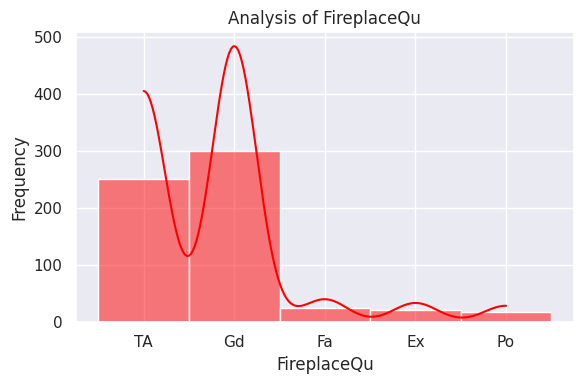

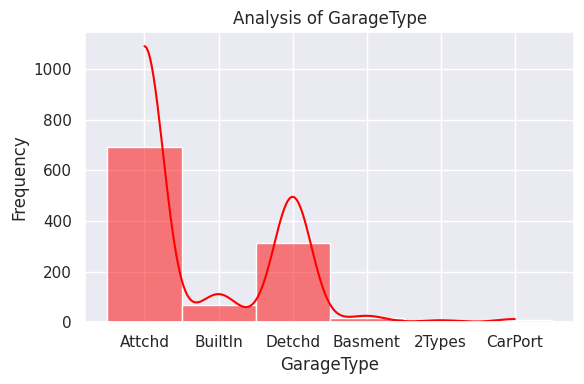

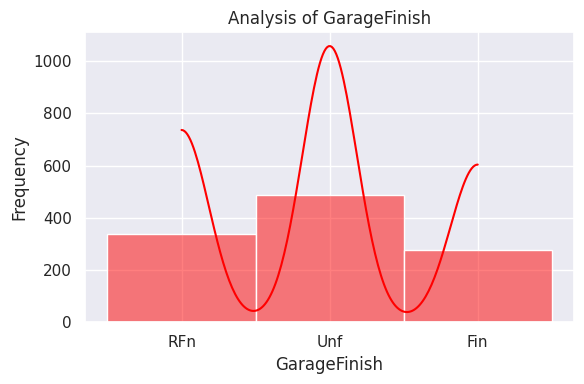

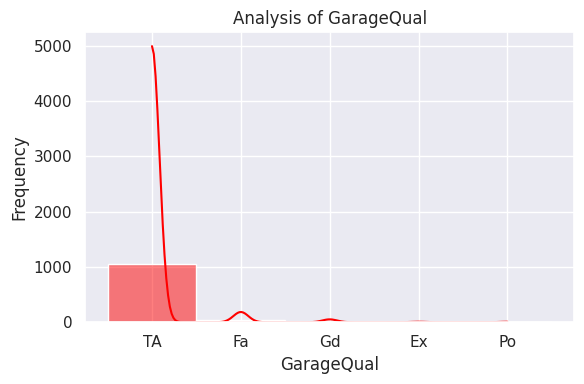

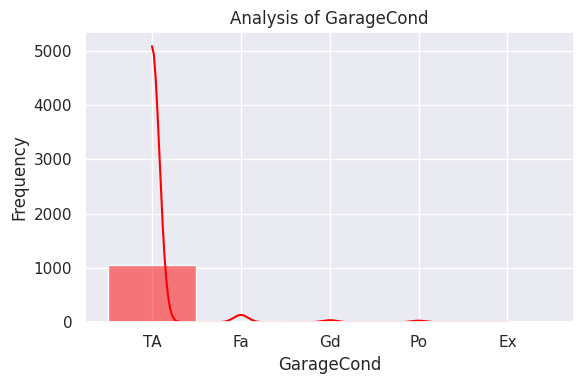

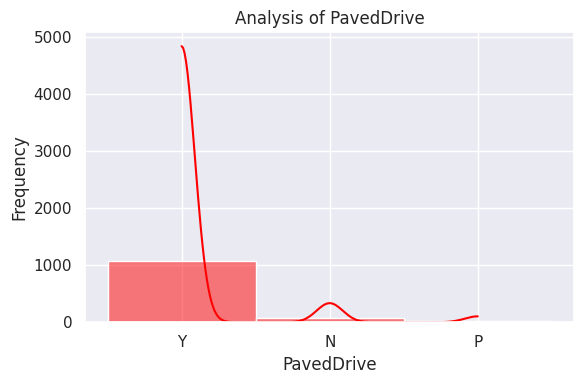

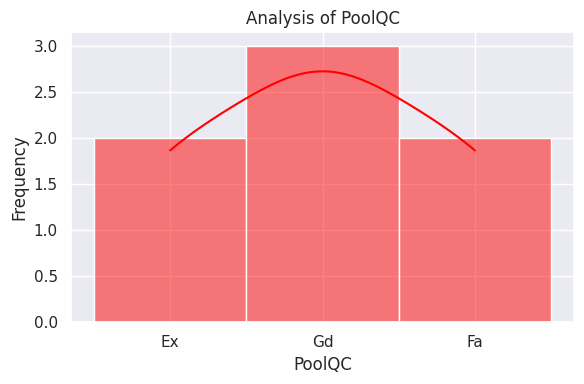

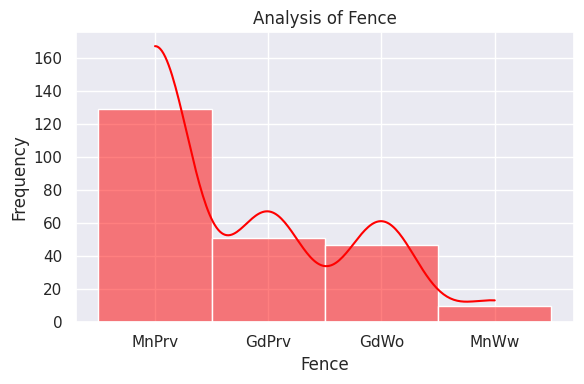

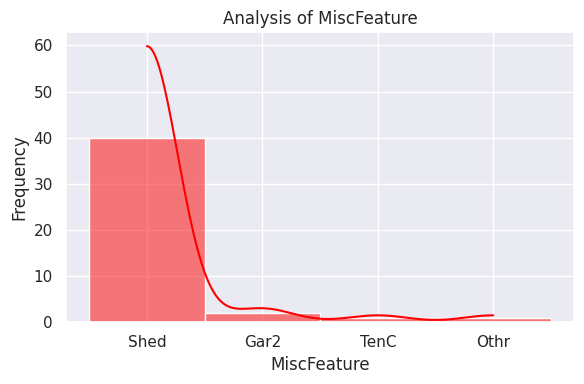

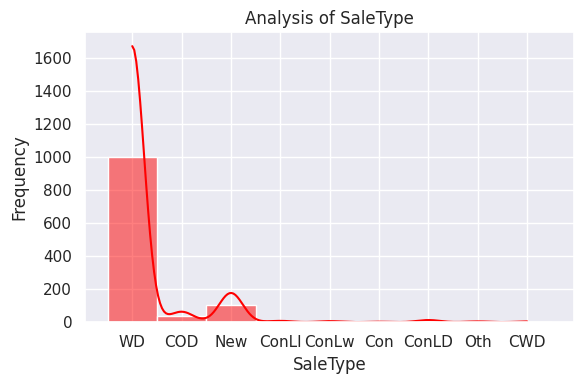

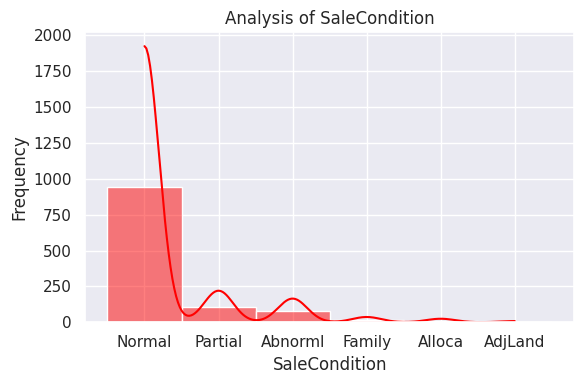

In [ ]:
for i in categoricalData_columns:
  plt.figure(figsize = (6,4))
  sns.histplot(train_data[i], color = "red", kde = True, bins = 4)
  plt.title(f"Analysis of {i}")
  plt.xlabel(f"{i}")
  plt.ylabel("Frequency")
  plt.tight_layout()
  plt.show()

# **Feature Engineering**

In [ ]:
copied_data = train_data.copy()

# Handling Missing Values

In [ ]:
missing_features = [features  for features in train_data.columns  if train_data[features].isnull().sum() > 1]
missing_features

['LotFrontage',
 'Alley',
 'MasVnrType',
 'MasVnrArea',
 'BsmtQual',
 'BsmtCond',
 'BsmtExposure',
 'BsmtFinType1',
 'BsmtFinType2',
 'FireplaceQu',
 'GarageType',
 'GarageYrBlt',
 'GarageFinish',
 'GarageQual',
 'GarageCond',
 'PoolQC',
 'Fence',
 'MiscFeature']

# Numerical Features

In [ ]:
numerical_missing = train_data[missing_features].select_dtypes(include = np.number)
numerical_missing.columns

Index(['LotFrontage', 'MasVnrArea', 'GarageYrBlt'], dtype='object')

In [ ]:
copied_data = train_data.copy()
handled_numericalfeature = []
for i in numerical_missing:
  train_data[i].fillna(train_data[i].median(),inplace = True)
  handled_numericalfeature.append(i)

In [ ]:
print(handled_numericalfeature)

['LotFrontage', 'MasVnrArea', 'GarageYrBlt']


In [ ]:
train_data['LotFrontage'].isnull().sum()


0

# Categorical Features

In [ ]:
categoricalData_columns.columns

Index(['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'LotConfig',
       'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType',
       'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd',
       'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual',
       'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating',
       'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual', 'Functional',
       'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond',
       'PavedDrive', 'PoolQC', 'Fence', 'MiscFeature', 'SaleType',
       'SaleCondition'],
      dtype='object')

In [ ]:
categorical_missing = train_data[missing_features].select_dtypes(include = object)
categorical_missing.columns

Index(['Alley', 'MasVnrType', 'BsmtQual', 'BsmtCond', 'BsmtExposure',
       'BsmtFinType1', 'BsmtFinType2', 'FireplaceQu', 'GarageType',
       'GarageFinish', 'GarageQual', 'GarageCond', 'PoolQC', 'Fence',
       'MiscFeature'],
      dtype='object')

In [ ]:
copied_data = train_data.copy()
handled_catergoricalfeature = []
for i in categorical_missing:
  train_data[i].fillna("missing",inplace = True)
  handled_catergoricalfeature.append(i)

In [ ]:
train_data.head(100)

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,LotConfig,LandSlope,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,120,RL,70.0,4928,Pave,missing,IR1,Lvl,Inside,Gtl,...,0,missing,missing,missing,0,2,2007,WD,Normal,128000
1,20,RL,95.0,15865,Pave,missing,IR1,Lvl,Inside,Mod,...,0,missing,missing,missing,0,10,2007,WD,Normal,268000
2,60,RL,92.0,9920,Pave,missing,IR1,Lvl,CulDSac,Gtl,...,0,missing,missing,missing,0,6,2007,WD,Normal,269790
3,20,RL,105.0,11751,Pave,missing,IR1,Lvl,Inside,Gtl,...,0,missing,MnPrv,missing,0,1,2010,COD,Normal,190000
4,20,RL,70.0,16635,Pave,missing,IR1,Lvl,FR2,Gtl,...,0,missing,missing,missing,0,6,2009,WD,Normal,215000
5,60,RL,58.0,14054,Pave,missing,IR1,Lvl,Inside,Gtl,...,0,missing,missing,missing,0,11,2006,New,Partial,219210
6,20,RL,70.0,11341,Pave,missing,IR1,Lvl,Inside,Gtl,...,0,missing,missing,missing,0,5,2010,WD,Normal,121500
7,20,RL,88.0,13125,Pave,missing,Reg,Lvl,Corner,Gtl,...,0,missing,GdPrv,missing,0,1,2006,WD,Normal,155000
8,20,RL,70.0,9170,Pave,missing,Reg,Lvl,Corner,Gtl,...,0,missing,GdPrv,Shed,400,4,2007,WD,Normal,140000
9,50,RL,80.0,8480,Pave,missing,Reg,Lvl,Inside,Gtl,...,0,missing,missing,missing,0,10,2008,COD,Abnorml,118500


# Handling Numerical Feature

In [ ]:
for feature in ['YearBuilt','YearRemodAdd','GarageYrBlt']:
    train_data[feature]=train_data['YrSold']-train_data[feature]

In [ ]:
train_data.head(100)

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,LotConfig,LandSlope,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,120,RL,70.0,4928,Pave,missing,IR1,Lvl,Inside,Gtl,...,0,missing,missing,missing,0,2,2007,WD,Normal,128000
1,20,RL,95.0,15865,Pave,missing,IR1,Lvl,Inside,Mod,...,0,missing,missing,missing,0,10,2007,WD,Normal,268000
2,60,RL,92.0,9920,Pave,missing,IR1,Lvl,CulDSac,Gtl,...,0,missing,missing,missing,0,6,2007,WD,Normal,269790
3,20,RL,105.0,11751,Pave,missing,IR1,Lvl,Inside,Gtl,...,0,missing,MnPrv,missing,0,1,2010,COD,Normal,190000
4,20,RL,70.0,16635,Pave,missing,IR1,Lvl,FR2,Gtl,...,0,missing,missing,missing,0,6,2009,WD,Normal,215000
5,60,RL,58.0,14054,Pave,missing,IR1,Lvl,Inside,Gtl,...,0,missing,missing,missing,0,11,2006,New,Partial,219210
6,20,RL,70.0,11341,Pave,missing,IR1,Lvl,Inside,Gtl,...,0,missing,missing,missing,0,5,2010,WD,Normal,121500
7,20,RL,88.0,13125,Pave,missing,Reg,Lvl,Corner,Gtl,...,0,missing,GdPrv,missing,0,1,2006,WD,Normal,155000
8,20,RL,70.0,9170,Pave,missing,Reg,Lvl,Corner,Gtl,...,0,missing,GdPrv,Shed,400,4,2007,WD,Normal,140000
9,50,RL,80.0,8480,Pave,missing,Reg,Lvl,Inside,Gtl,...,0,missing,missing,missing,0,10,2008,COD,Abnorml,118500


In [ ]:
train_data[['YearBuilt','YearRemodAdd','GarageYrBlt']].head()


,YearBuilt,YearRemodAdd,GarageYrBlt
0,31,31,30.0
1,37,37,37.0
2,11,10,10.0
3,33,33,33.0
4,32,9,32.0


In [ ]:
numericalData_columns.columns

Index(['MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond',
       'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2',
       'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF',
       'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath',
       'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces',
       'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF',
       'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal',
       'MoSold', 'YrSold', 'SalePrice'],
      dtype='object')

# Encoding the Categorical Features

In [ ]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()
for i in categoricalData_columns:
   train_data[i] = label_encoder.fit_transform(train_data[i])

In [ ]:
train_data.head(100)

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,LotConfig,LandSlope,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,120,3,70.0,4928,1,2,0,3,4,0,...,0,3,4,4,0,2,2007,8,4,128000
1,20,3,95.0,15865,1,2,0,3,4,1,...,0,3,4,4,0,10,2007,8,4,268000
2,60,3,92.0,9920,1,2,0,3,1,0,...,0,3,4,4,0,6,2007,8,4,269790
3,20,3,105.0,11751,1,2,0,3,4,0,...,0,3,2,4,0,1,2010,0,4,190000
4,20,3,70.0,16635,1,2,0,3,2,0,...,0,3,4,4,0,6,2009,8,4,215000
5,60,3,58.0,14054,1,2,0,3,4,0,...,0,3,4,4,0,11,2006,6,5,219210
6,20,3,70.0,11341,1,2,0,3,4,0,...,0,3,4,4,0,5,2010,8,4,121500
7,20,3,88.0,13125,1,2,3,3,0,0,...,0,3,0,4,0,1,2006,8,4,155000
8,20,3,70.0,9170,1,2,3,3,0,0,...,0,3,0,2,400,4,2007,8,4,140000
9,50,3,80.0,8480,1,2,3,3,4,0,...,0,3,4,4,0,10,2008,0,0,118500


# Feature Scaling

In [ ]:
scaling_feature=[feature for feature in train_data.columns if feature not in ['SalePrice'] ]
len(scaling_feature)

78

In [ ]:
scaling_feature


['MSSubClass',
 'MSZoning',
 'LotFrontage',
 'LotArea',
 'Street',
 'Alley',
 'LotShape',
 'LandContour',
 'LotConfig',
 'LandSlope',
 'Neighborhood',
 'Condition1',
 'Condition2',
 'BldgType',
 'HouseStyle',
 'OverallQual',
 'OverallCond',
 'YearBuilt',
 'YearRemodAdd',
 'RoofStyle',
 'RoofMatl',
 'Exterior1st',
 'Exterior2nd',
 'MasVnrType',
 'MasVnrArea',
 'ExterQual',
 'ExterCond',
 'Foundation',
 'BsmtQual',
 'BsmtCond',
 'BsmtExposure',
 'BsmtFinType1',
 'BsmtFinSF1',
 'BsmtFinType2',
 'BsmtFinSF2',
 'BsmtUnfSF',
 'TotalBsmtSF',
 'Heating',
 'HeatingQC',
 'CentralAir',
 'Electrical',
 '1stFlrSF',
 '2ndFlrSF',
 'LowQualFinSF',
 'GrLivArea',
 'BsmtFullBath',
 'BsmtHalfBath',
 'FullBath',
 'HalfBath',
 'BedroomAbvGr',
 'KitchenAbvGr',
 'KitchenQual',
 'TotRmsAbvGrd',
 'Functional',
 'Fireplaces',
 'FireplaceQu',
 'GarageType',
 'GarageYrBlt',
 'GarageFinish',
 'GarageCars',
 'GarageArea',
 'GarageQual',
 'GarageCond',
 'PavedDrive',
 'WoodDeckSF',
 'OpenPorchSF',
 'EnclosedPorch',
 

In [ ]:
feature_scale=[feature for feature in train_data.columns if feature not in ['Id','SalePrice']]

from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
scaler.fit(train_data[feature_scale])

StandardScaler()

In [ ]:
scaler.transform(train_data[feature_scale])


array([[ 1.50830058, -0.02164599, -0.03599365, ..., -0.60548713,
         0.33003329,  0.20793187],
       [-0.87704243, -0.02164599,  1.07854983, ..., -0.60548713,
         0.33003329,  0.20793187],
       [ 0.07709478, -0.02164599,  0.94480461, ..., -0.60548713,
         0.33003329,  0.20793187],
       ...,
       [ 2.46243779, -0.02164599, -2.08675364, ...,  0.8992128 ,
         0.33003329,  0.20793187],
       [ 0.31562908, -4.76211672, -0.92762843, ...,  0.14686284,
         0.33003329,  0.20793187],
       [ 0.07709478, -0.02164599, -0.03599365, ..., -1.3578371 ,
         0.33003329,  0.20793187]])

In [ ]:
data = pd.concat([train_data[['SalePrice']].reset_index(drop=True),
                    pd.DataFrame(scaler.transform(train_data[feature_scale]), columns=feature_scale)],
                    axis=1)

In [ ]:
data.head(100)

,SalePrice,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,LotConfig,...,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition
0,128000,1.508301,-0.021646,-0.035994,-0.620616,0.058621,0.251762,-1.373107,0.318473,0.606420,...,-0.273377,-0.076845,0.070812,0.472132,0.192896,-0.087131,-1.617822,-0.605487,0.330033,0.207932
1,268000,-0.877042,-0.021646,1.078550,0.600903,0.058621,0.251762,-1.373107,0.318473,0.606420,...,3.795117,-0.076845,0.070812,0.472132,0.192896,-0.087131,1.361470,-0.605487,0.330033,0.207932
2,269790,0.077095,-0.021646,0.944805,-0.063075,0.058621,0.251762,-1.373107,0.318473,-1.220661,...,-0.273377,-0.076845,0.070812,0.472132,0.192896,-0.087131,-0.128176,-0.605487,0.330033,0.207932
3,190000,-0.877042,-0.021646,1.524367,0.141424,0.058621,0.251762,-1.373107,0.318473,0.606420,...,-0.273377,-0.076845,0.070812,-1.327054,0.192896,-0.087131,-1.990233,1.651563,-4.612004,0.207932
4,215000,-0.877042,-0.021646,-0.035994,0.686902,0.058621,0.251762,-1.373107,0.318473,-0.611634,...,-0.273377,-0.076845,0.070812,0.472132,0.192896,-0.087131,-0.128176,0.899213,0.330033,0.207932
5,219210,0.077095,-0.021646,-0.570975,0.398638,0.058621,0.251762,-1.373107,0.318473,0.606420,...,-0.273377,-0.076845,0.070812,0.472132,0.192896,-0.087131,1.733882,-1.357837,-0.905476,1.107430
6,121500,-0.877042,-0.021646,-0.035994,0.095632,0.058621,0.251762,-1.373107,0.318473,0.606420,...,1.452100,-0.076845,0.070812,0.472132,0.192896,-0.087131,-0.500587,1.651563,0.330033,0.207932
7,155000,-0.877042,-0.021646,0.766478,0.294881,0.058621,0.251762,0.752055,0.318473,-1.829688,...,-0.273377,-0.076845,0.070812,-3.126240,0.192896,-0.087131,-1.990233,-1.357837,0.330033,0.207932
8,140000,-0.877042,-0.021646,-0.035994,-0.146840,0.058621,0.251762,0.752055,0.318473,-1.829688,...,-0.273377,-0.076845,0.070812,-3.126240,-4.704992,0.649474,-0.872999,-0.605487,0.330033,0.207932
9,118500,-0.161440,-0.021646,0.409824,-0.223904,0.058621,0.251762,0.752055,0.318473,0.606420,...,-0.273377,-0.076845,0.070812,0.472132,0.192896,-0.087131,1.361470,0.146863,-4.612004,-3.390060


In [ ]:
train_data = data

In [ ]:
copied_data = train_data

In [ ]:
train_data.shape

(1168, 79)

# Feature Selection

In [ ]:
X = train_data.drop(['SalePrice'],axis=1)

In [ ]:
y = train_data[['SalePrice']]


In [ ]:
from sklearn.linear_model import Lasso
from sklearn.feature_selection import SelectFromModel

feature_sel_model = SelectFromModel(Lasso(alpha=0.005, random_state=0))
feature_sel_model.fit(X, y)

/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_coordinate_descent.py:628: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.937e+10, tolerance: 7.303e+08
  model = cd_fast.enet_coordinate_descent(


SelectFromModel(estimator=Lasso(alpha=0.005, random_state=0))

In [ ]:
feature_sel_model.get_support()


array([ True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True])

In [ ]:
selected_feat = X.columns[(feature_sel_model.get_support())]

print('total features: {}'.format((X.shape[1])))
print('selected features: {}'.format(len(selected_feat)))


total features: 78
selected features: 78


In [ ]:
selected_feat

Index(['MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street', 'Alley',
       'LotShape', 'LandContour', 'LotConfig', 'LandSlope', 'Neighborhood',
       'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'OverallQual',
       'OverallCond', 'YearBuilt', 'YearRemodAdd', 'RoofStyle', 'RoofMatl',
       'Exterior1st', 'Exterior2nd', 'MasVnrType', 'MasVnrArea', 'ExterQual',
       'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure',
       'BsmtFinType1', 'BsmtFinSF1', 'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF',
       'TotalBsmtSF', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical',
       '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath',
       'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr',
       'KitchenQual', 'TotRmsAbvGrd', 'Functional', 'Fireplaces',
       'FireplaceQu', 'GarageType', 'GarageYrBlt', 'GarageFinish',
       'GarageCars', 'GarageArea', 'GarageQual', 'GarageCond', 'PavedDrive',
       'WoodDeckSF', 'O

In [ ]:
X=X[selected_feat]


In [ ]:
X.head()


,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,LotConfig,LandSlope,...,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition
0,1.508301,-0.021646,-0.035994,-0.620616,0.058621,0.251762,-1.373107,0.318473,0.606420,-0.226126,...,-0.273377,-0.076845,0.070812,0.472132,0.192896,-0.087131,-1.617822,-0.605487,0.330033,0.207932
1,-0.877042,-0.021646,1.078550,0.600903,0.058621,0.251762,-1.373107,0.318473,0.606420,3.295414,...,3.795117,-0.076845,0.070812,0.472132,0.192896,-0.087131,1.361470,-0.605487,0.330033,0.207932
2,0.077095,-0.021646,0.944805,-0.063075,0.058621,0.251762,-1.373107,0.318473,-1.220661,-0.226126,...,-0.273377,-0.076845,0.070812,0.472132,0.192896,-0.087131,-0.128176,-0.605487,0.330033,0.207932
3,-0.877042,-0.021646,1.524367,0.141424,0.058621,0.251762,-1.373107,0.318473,0.606420,-0.226126,...,-0.273377,-0.076845,0.070812,-1.327054,0.192896,-0.087131,-1.990233,1.651563,-4.612004,0.207932
4,-0.877042,-0.021646,-0.035994,0.686902,0.058621,0.251762,-1.373107,0.318473,-0.611634,-0.226126,...,-0.273377,-0.076845,0.070812,0.472132,0.192896,-0.087131,-0.128176,0.899213,0.330033,0.207932


In [ ]:
X.shape

(1168, 78)

In [ ]:
y.head()

,SalePrice
0,128000
1,268000
2,269790
3,190000
4,215000


In [ ]:
minimum = min(train_data["SalePrice"])
minimum


34900

In [ ]:
maximum = max(train_data["SalePrice"])
maximum

755000

#**Building the Model**

In [ ]:
from sklearn.model_selection import train_test_split
X_train,X_test, y_train, y_test = train_test_split(X,y, test_size = 0.3, random_state=42)

In [ ]:
print(X_train.shape,X_test.shape,y_train.shape,y_test.shape)

(817, 78) (351, 78) (817, 1) (351, 1)


In [ ]:
y_train.head()

,SalePrice
593,129000
788,169990
490,219500
654,108000
963,119000


# **Linear Regression**

In [ ]:
from sklearn.linear_model import LinearRegression
regressor = LinearRegression()
regressor.fit(X_train,y_train)

LinearRegression()

In [ ]:
y_pred = regressor.predict(X_test)
y_pred


array([[205494.19325979],
       [118885.10147896],
       [ 62106.00398946],
       [190913.44098741],
       [ 97250.6860742 ],
       [341485.54490526],
       [178054.11330598],
       [163428.93526061],
       [137194.67053932],
       [229832.40162668],
       [135898.14083419],
       [229364.03640614],
       [216086.54794841],
       [227583.59132284],
       [140254.11008183],
       [277672.41173794],
       [101342.05317911],
       [273747.83397835],
       [136643.29609753],
       [177432.09410554],
       [172508.2580199 ],
       [337598.02312922],
       [215129.50872871],
       [140929.68157158],
       [171779.11486574],
       [118275.35231475],
       [130617.77666963],
       [162194.85471664],
       [280143.08467964],
       [186438.21238551],
       [178208.69167595],
       [191801.306686  ],
       [110287.04448602],
       [130809.91275491],
       [130352.28949905],
       [227101.96098214],
       [178144.28500983],
       [131438.70603798],
       [ 999

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)


In [ ]:
print(round(mse,2))
print(round(mae,2))
print(round(r2,2))


1698875473.44
22276.7
0.75


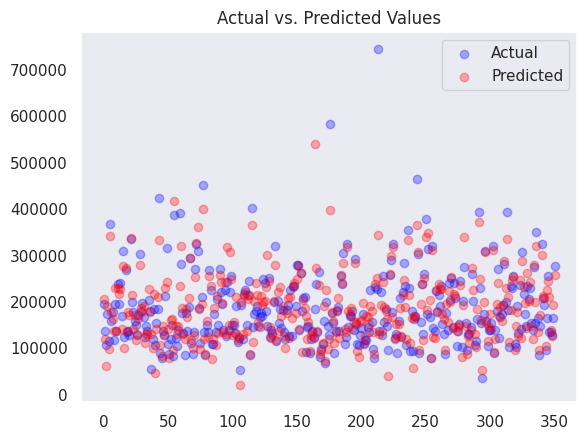

In [ ]:
plt.scatter(range(len(y_test)), y_test, c='blue', label='Actual', alpha=0.3)
plt.scatter(range(len(y_pred)), y_pred, c='red', label='Predicted', alpha=0.3)
plt.title("Actual vs. Predicted Values")
plt.legend()
plt.grid()
plt.show()

#**Random Forest Regression**

In [ ]:
from sklearn.ensemble import RandomForestRegressor
rfr = RandomForestRegressor(random_state=42)
rfr.fit(X_train, y_train)


/usr/local/lib/python3.10/dist-packages/sklearn/base.py:1152: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


RandomForestRegressor(random_state=42)

In [ ]:
y_pred1 = rfr.predict(X_test)
y_pred1


array([182255.86, 137100.25, 102536.97, 185406.55, 117487.34, 339496.7 ,
       135024.33, 150863.86, 117068.41, 217553.33, 134091.91, 207981.24,
       194711.05, 228911.47, 151545.15, 302065.69, 130018.94, 264546.89,
       139749.02, 140796.37, 161931.44, 327315.6 , 249418.57, 150024.64,
       170817.03, 134408.25, 140206.33, 164817.48, 256847.33, 168497.85,
       159877.5 , 168961.37, 129836.25, 116451.56, 140804.5 , 223779.18,
       157018.04, 102191.58, 115929.17, 195360.92, 105917.49, 144861.98,
       197370.83, 383024.55, 100536.22,  96414.  , 162031.44, 124881.54,
       190427.  , 304259.78, 121894.4 , 113041.58, 121779.3 , 141807.25,
        86420.58, 436448.36, 176475.7 , 138272.6 , 143112.75, 227222.81,
       283548.15, 150783.34, 134045.17, 104686.01, 163369.88, 157676.54,
       200037.55, 294195.86, 120094.93, 100937.83, 129943.  , 257696.07,
       349545.18, 326836.32, 164593.98,  90398.21, 195649.18, 397582.26,
       131544.25, 104030.  , 141762.  , 135945.  , 

In [ ]:
mae = mean_absolute_error(y_test, y_pred1)
mse = mean_squared_error(y_test, y_pred1)
r2 = r2_score(y_test, y_pred1)

In [ ]:
print(round(mse,2))
print(round(mae,2))
print(round(r2,2))


1152895262.68
19153.74
0.83


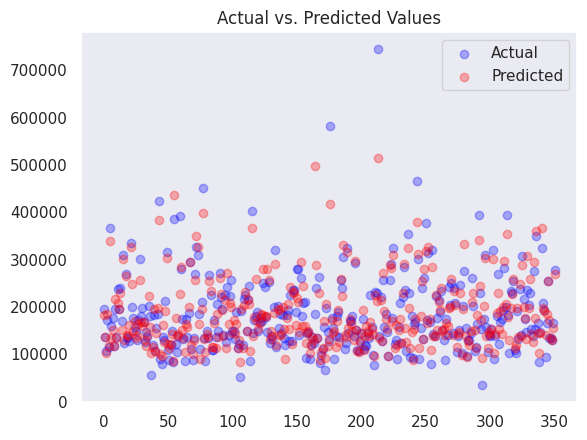

In [ ]:
plt.scatter(range(len(y_test)), y_test, c='blue', label='Actual', alpha=0.3)
plt.scatter(range(len(y_pred1)), y_pred1, c='red', label='Predicted', alpha=0.3)
plt.title("Actual vs. Predicted Values")
plt.legend()
plt.grid()
plt.show()

# **Decision Tree Regressor**

In [ ]:
from sklearn.tree import DecisionTreeRegressor

reg = DecisionTreeRegressor(max_depth=10)
reg.fit(X_train, y_train)

DecisionTreeRegressor(max_depth=10)

In [ ]:
y_pred2 = reg.predict(X_test)
y_pred2

array([174147.45454545, 133225.        , 101652.        , 179262.19230769,
        91250.        , 392500.        , 161833.33333333, 139600.        ,
       120450.        , 216380.        , 133225.        , 169134.375     ,
       188333.33333333, 205000.        , 139500.        , 252000.        ,
       155071.73913043, 283463.        , 135440.58333333, 129500.        ,
       185000.        , 337000.        , 274400.        , 152500.        ,
       210000.        , 134368.18181818, 133225.        , 164850.        ,
       171000.        , 194116.66666667, 155071.73913043, 140833.33333333,
       119200.        ,  84500.        , 134368.18181818, 221750.        ,
       144283.33333333,  66500.        , 124325.        , 189808.02857143,
        84000.        , 130000.        , 189808.02857143, 315000.        ,
       122782.14285714, 111758.33333333, 193500.        , 122782.14285714,
       188333.33333333, 350000.        , 109490.        , 124325.        ,
       125625.        , 1

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
mae = mean_absolute_error(y_test, y_pred2)
mse = mean_squared_error(y_test, y_pred2)
r2 = r2_score(y_test, y_pred2)

In [ ]:
print(round(mse,2))
print(round(mae,2))
print(round(r2,2))

1809090543.33
26831.91
0.73


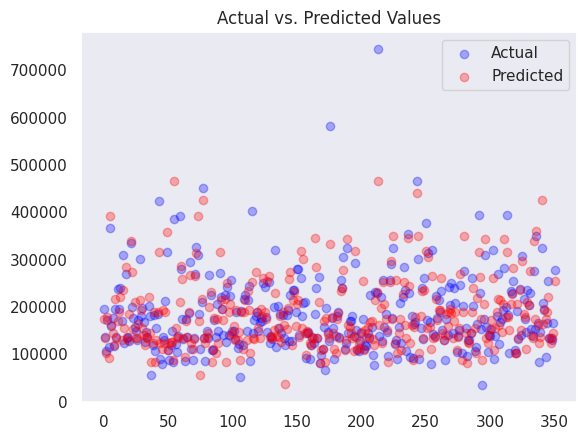

In [ ]:
plt.scatter(range(len(y_test)), y_test, c='blue', label='Actual', alpha=0.3)
plt.scatter(range(len(y_pred2)), y_pred2, c='red', label='Predicted', alpha=0.3)
plt.title("Actual vs. Predicted Values")
plt.legend()
plt.grid()
plt.show()

# **Neural Netoworks : Multilayer Perceptron with GridSearchCV**

In [ ]:
from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import GridSearchCV

In [ ]:

model = MLPRegressor(hidden_layer_sizes=(100,), activation='relu', solver='adam',max_iter=20)

param_grid = {
    'batch_size': [16, 32],
    'learning_rate_init': [0.001, 0.01]
}


In [ ]:
grid_search = GridSearchCV(estimator= model, param_grid=param_grid, cv=3)
grid_search.fit(X_train, y_train)

/usr/local/lib/python3.10/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:1625: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/usr/local/lib/python3.10/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:1625: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/usr/local/lib/python3.10/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converge

GridSearchCV(cv=3, estimator=MLPRegressor(max_iter=20),
             param_grid={'batch_size': [16, 32],
                         'learning_rate_init': [0.001, 0.01]})

In [ ]:
best_model = grid_search.best_estimator_
best_model

MLPRegressor(batch_size=16, learning_rate_init=0.01, max_iter=20)

In [ ]:
y_pred3 = best_model.predict(X_test)
y_pred3

array([135746.81820735, 104975.08273084, 128031.80597184, 101046.63768717,
        91827.24704348, 274669.90715974,  85708.62037414, 108267.16384602,
       111902.49915124, 130022.52288012,  52303.47416867,  89912.02904603,
        94142.96929169, 164716.75543576,  55438.87893316, 164168.89867809,
        92752.48400828, 215738.45631396, 141166.45169551,  54346.44636015,
        41264.94963039, 257170.11725237,  34350.25861152,  79328.47208336,
        37862.13879587,  91509.54154438,  58461.92944783,  59856.03308105,
       133181.3843254 ,  40271.02123886,  59122.6183463 ,  69524.49086316,
        97399.90824843,  53368.38100156,  35375.69870731, 128444.48615412,
        50259.7207077 ,  26868.09454761, 111785.99303222, 131725.59844481,
       152084.21809877, 110945.18314319,  85869.39147127, 305880.76192729,
        62149.96792952, 130719.78002668,  51768.43881883,  93543.37610372,
       106586.80813151,  36258.20447715,  95587.35921358, 120854.99121853,
       121459.80325689,  

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
mae = mean_absolute_error(y_test, y_pred3)
mse = mean_squared_error(y_test, y_pred3)
r2 = r2_score(y_test, y_pred3)

In [ ]:
print(round(mse,2))
print(round(mae,2))
print(round(r2,2))

10397041302.91
84642.44
-0.56


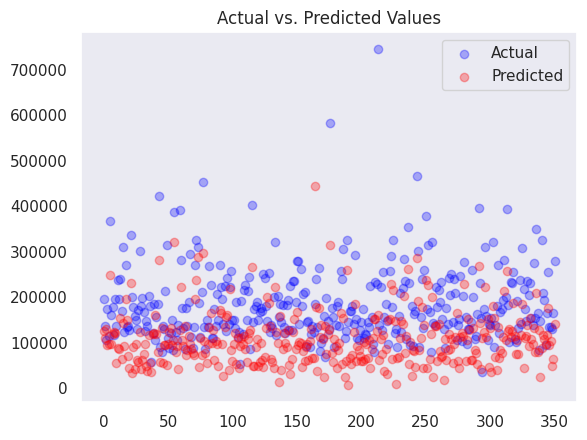

In [ ]:
plt.scatter(range(len(y_test)), y_test, c='blue', label='Actual', alpha=0.3)
plt.scatter(range(len(y_pred3)), y_pred3, c='red', label='Predicted', alpha=0.3)
plt.title("Actual vs. Predicted Values")
plt.legend()
plt.grid()
plt.show()

# **Gradient Boosting**

In [ ]:
from sklearn.ensemble import GradientBoostingRegressor

gbr = GradientBoostingRegressor(loss='squared_error',
                                learning_rate=0.1,
                                n_estimators=300,
                                max_depth = 1
                              )

In [ ]:
gbr.fit(X_train,y_train)

/usr/local/lib/python3.10/dist-packages/sklearn/ensemble/_gb.py:424: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


GradientBoostingRegressor(max_depth=1, n_estimators=300)

In [ ]:
y_pred4 = gbr.predict(X_test)
y_pred4

array([165154.44168228, 137082.00742927, 100971.60989077, 164348.72690346,
       111746.12799151, 375565.02304694, 141468.35809804, 150896.41982655,
       121796.07757063, 208009.2443662 , 132360.61297114, 221643.24552074,
       200995.44423232, 233570.42072406, 159646.48477008, 311708.94398661,
       123125.92574328, 283845.29633827, 138233.46132858, 143718.9256092 ,
       160041.99564613, 308519.55112535, 223197.39986151, 159327.08327001,
       193915.70683427, 132592.26294376, 132451.21589242, 151708.23350888,
       253916.76301285, 165272.97326314, 166624.60250947, 174343.54017823,
       123847.58695384, 135282.20745691, 131820.00048074, 240672.89708611,
       159463.02370649, 108144.28237865, 111734.92443068, 191527.4329987 ,
       102969.20549732, 126933.85694299, 196969.64764754, 382931.65970452,
        90662.2235466 ,  96655.722484  , 148841.68715212, 140880.99186214,
       197141.22784483, 290660.80790697, 117030.14381338,  96847.35353513,
       129129.26759192, 1

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
mae = mean_absolute_error(y_test, y_pred4)
mse = mean_squared_error(y_test, y_pred4)
r2 = r2_score(y_test, y_pred4)

In [ ]:
print(round(mse,2))
print(round(mae,2))
print(round(r2,2))

1221447156.68
19344.37
0.82


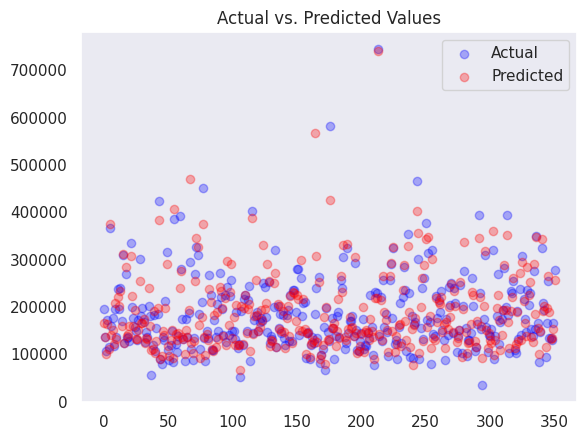

In [ ]:
plt.scatter(range(len(y_test)), y_test, c='blue', label='Actual', alpha=0.3)
plt.scatter(range(len(y_pred4)), y_pred4, c='red', label='Predicted', alpha=0.3)
plt.title("Actual vs. Predicted Values")
plt.legend()
plt.grid()
plt.show()

# **Importing Testing testing dataset**

In [ ]:
test_data = pd.read_csv("Hosuing-project-test-data.csv")

In [ ]:
test_data.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition
0,337,20,RL,86.0,14157,Pave,NaN,IR1,HLS,AllPub,...,0,0,NaN,NaN,NaN,0,7,2007,WD,Normal
1,1018,120,RL,NaN,5814,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,8,2009,COD,Abnorml
2,929,20,RL,NaN,11838,Pave,NaN,Reg,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,6,2009,WD,Normal
3,1148,70,RL,75.0,12000,Pave,NaN,Reg,Bnk,AllPub,...,0,0,NaN,NaN,NaN,0,7,2009,WD,Normal
4,1227,60,RL,86.0,14598,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,1,2008,WD,Normal


In [ ]:
test_data.dtypes

,0
Id,int64
MSSubClass,int64
MSZoning,object
LotFrontage,float64
LotArea,int64
Street,object
Alley,object
LotShape,object
LandContour,object
Utilities,object


In [ ]:
test_data["PoolQC"] = test_data["PoolQC"].astype(object)

In [ ]:
test_data.drop(columns= ["Id","Utilities"],inplace=True)

In [ ]:
numericalData_columns1 = test_data.select_dtypes(include=np.number)
categoricalData_columns1 = test_data.select_dtypes(include="object")

print("NUMERICAL COLUMNS:",numericalData_columns1.columns)
print("==============================================================================")

print("CATEGORICAL COLUMNS:",categoricalData_columns1.columns)

NUMERICAL COLUMNS: Index(['MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond',
       'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2',
       'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF',
       'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath',
       'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces',
       'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF',
       'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal',
       'MoSold', 'YrSold'],
      dtype='object')
CATEGORICAL COLUMNS: Index(['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'LotConfig',
       'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType',
       'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd',
       'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual',
       'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating',


In [ ]:
test_data.shape

(292, 78)

# **Handling Missing Values**

In [ ]:
test_data.isnull().sum()

,0
MSSubClass,0
MSZoning,0
LotFrontage,45
LotArea,0
Street,0
Alley,278
LotShape,0
LandContour,0
LotConfig,0
LandSlope,0


# **Handling Missing Features**

In [ ]:
missing_features1 = [features  for features in test_data.columns  if test_data[features].isnull().sum() > 1]
missing_features1

['LotFrontage',
 'Alley',
 'MasVnrType',
 'BsmtQual',
 'BsmtCond',
 'BsmtExposure',
 'BsmtFinType1',
 'BsmtFinType2',
 'FireplaceQu',
 'GarageType',
 'GarageYrBlt',
 'GarageFinish',
 'GarageQual',
 'GarageCond',
 'PoolQC',
 'Fence',
 'MiscFeature']

In [ ]:
numerical_missing1 = test_data[missing_features1].select_dtypes(include = np.number)
numerical_missing1.columns

Index(['LotFrontage', 'GarageYrBlt'], dtype='object')

In [ ]:
handled_numericalfeature1 = []
for i in numerical_missing1:
  test_data[i].fillna(test_data[i].median(),inplace = True)
  handled_numericalfeature1.append(i)

In [ ]:
handled_numericalfeature1

['LotFrontage', 'GarageYrBlt']

In [ ]:
categorical_missing1 = test_data[missing_features1].select_dtypes(include = object)
categorical_missing1.columns


Index(['Alley', 'MasVnrType', 'BsmtQual', 'BsmtCond', 'BsmtExposure',
       'BsmtFinType1', 'BsmtFinType2', 'FireplaceQu', 'GarageType',
       'GarageFinish', 'GarageQual', 'GarageCond', 'PoolQC', 'Fence',
       'MiscFeature'],
      dtype='object')

In [ ]:
handled_catergoricalfeature1 = []
for i in categorical_missing1:
  test_data[i].fillna("missing",inplace = True)
  handled_catergoricalfeature1.append(i)

In [ ]:
handled_catergoricalfeature1

['Alley',
 'MasVnrType',
 'BsmtQual',
 'BsmtCond',
 'BsmtExposure',
 'BsmtFinType1',
 'BsmtFinType2',
 'FireplaceQu',
 'GarageType',
 'GarageFinish',
 'GarageQual',
 'GarageCond',
 'PoolQC',
 'Fence',
 'MiscFeature']

In [ ]:
test_data.head(100)

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,LotConfig,LandSlope,...,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition
0,20,RL,86.0,14157,Pave,missing,IR1,HLS,Corner,Gtl,...,0,0,missing,missing,missing,0,7,2007,WD,Normal
1,120,RL,65.0,5814,Pave,missing,IR1,Lvl,CulDSac,Gtl,...,0,0,missing,missing,missing,0,8,2009,COD,Abnorml
2,20,RL,65.0,11838,Pave,missing,Reg,Lvl,Inside,Gtl,...,0,0,missing,missing,missing,0,6,2009,WD,Normal
3,70,RL,75.0,12000,Pave,missing,Reg,Bnk,Inside,Gtl,...,0,0,missing,missing,missing,0,7,2009,WD,Normal
4,60,RL,86.0,14598,Pave,missing,IR1,Lvl,CulDSac,Gtl,...,0,0,missing,missing,missing,0,1,2008,WD,Normal
5,180,RM,21.0,1936,Pave,missing,Reg,Lvl,Inside,Gtl,...,0,0,missing,MnPrv,missing,0,12,2007,WD,Normal
6,180,RM,35.0,3675,Pave,missing,Reg,Lvl,Inside,Gtl,...,0,0,missing,missing,missing,0,5,2006,WD,Normal
7,20,RL,107.0,13891,Pave,missing,Reg,Lvl,Inside,Gtl,...,0,0,missing,missing,missing,0,1,2008,New,Partial
8,80,RL,65.0,12800,Pave,missing,Reg,Low,Inside,Mod,...,396,0,missing,missing,missing,0,8,2009,WD,Normal
9,120,RM,32.0,4500,Pave,missing,Reg,Lvl,FR2,Gtl,...,0,0,missing,missing,missing,0,6,2009,WD,Normal


In [ ]:

for feature in ['YearBuilt','YearRemodAdd','GarageYrBlt']:
    test_data[feature]=test_data['YrSold']-test_data[feature]

test_data[['YearBuilt','YearRemodAdd','GarageYrBlt']].head()


,YearBuilt,YearRemodAdd,GarageYrBlt
0,2,1,2.0
1,25,25,25.0
2,8,8,8.0
3,68,59,68.0
4,1,1,1.0


# **Encoding both numerical and categorical features**

In [ ]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()
for i in categoricalData_columns1:
    test_data[i] = label_encoder.fit_transform(test_data[i])


In [ ]:
test_data.head()

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,LotConfig,LandSlope,...,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition
0,20,2,86.0,14157,1,2,0,1,0,0,...,0,0,0,4,2,0,7,2007,5,2
1,120,2,65.0,5814,1,2,0,3,1,0,...,0,0,0,4,2,0,8,2009,0,0
2,20,2,65.0,11838,1,2,3,3,4,0,...,0,0,0,4,2,0,6,2009,5,2
3,70,2,75.0,12000,1,2,3,0,4,0,...,0,0,0,4,2,0,7,2009,5,2
4,60,2,86.0,14598,1,2,0,3,1,0,...,0,0,0,4,2,0,1,2008,5,2


In [ ]:
feature_scale1 = ['MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond',
       'YearBuilt','YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2',
       'BsmtUnfSF','TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF',
       'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath',
       'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces',
       'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF',
       'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal',
       'MoSold', 'YrSold','MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour',
       'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2',
       'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st',
       'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation',
       'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2',
       'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual',
       'Functional', 'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual',
       'GarageCond', 'PavedDrive', 'PoolQC', 'Fence', 'MiscFeature',
       'SaleType', 'SaleCondition']
feature_scale1

['MSSubClass',
 'LotFrontage',
 'LotArea',
 'OverallQual',
 'OverallCond',
 'YearBuilt',
 'YearRemodAdd',
 'MasVnrArea',
 'BsmtFinSF1',
 'BsmtFinSF2',
 'BsmtUnfSF',
 'TotalBsmtSF',
 '1stFlrSF',
 '2ndFlrSF',
 'LowQualFinSF',
 'GrLivArea',
 'BsmtFullBath',
 'BsmtHalfBath',
 'FullBath',
 'HalfBath',
 'BedroomAbvGr',
 'KitchenAbvGr',
 'TotRmsAbvGrd',
 'Fireplaces',
 'GarageYrBlt',
 'GarageCars',
 'GarageArea',
 'WoodDeckSF',
 'OpenPorchSF',
 'EnclosedPorch',
 '3SsnPorch',
 'ScreenPorch',
 'PoolArea',
 'MiscVal',
 'MoSold',
 'YrSold',
 'MSZoning',
 'Street',
 'Alley',
 'LotShape',
 'LandContour',
 'LotConfig',
 'LandSlope',
 'Neighborhood',
 'Condition1',
 'Condition2',
 'BldgType',
 'HouseStyle',
 'RoofStyle',
 'RoofMatl',
 'Exterior1st',
 'Exterior2nd',
 'MasVnrType',
 'ExterQual',
 'ExterCond',
 'Foundation',
 'BsmtQual',
 'BsmtCond',
 'BsmtExposure',
 'BsmtFinType1',
 'BsmtFinType2',
 'Heating',
 'HeatingQC',
 'CentralAir',
 'Electrical',
 'KitchenQual',
 'Functional',
 'FireplaceQu',
 

In [ ]:
len(feature_scale1)

78

In [ ]:

from sklearn.preprocessing import StandardScaler
scaler1 = StandardScaler()
scaler1.fit(test_data[feature_scale1])
scaler1.transform(test_data[feature_scale1])


array([[-0.85605433,  0.99228791,  0.2638941 , ...,  0.18145294,
         0.23029007,  0.14865423],
       [ 1.43198105, -0.06042999, -0.36303034, ...,  0.18145294,
        -6.49418003, -3.32390858],
       [-0.85605433, -0.06042999,  0.08963571, ...,  0.18145294,
         0.23029007,  0.14865423],
       ...,
       [-0.85605433, -0.06042999,  0.04477488, ..., -4.63529788,
         0.23029007,  0.14865423],
       [-0.16964372, -0.81237135, -0.42419737, ...,  0.18145294,
         0.23029007,  0.14865423],
       [ 2.3471952 , -2.26612464, -0.65316043, ...,  0.18145294,
         0.23029007,  0.14865423]])

In [ ]:
data = pd.DataFrame(scaler.transform(train_data[feature_scale]), columns=feature_scale)

In [ ]:
test_data = data

In [ ]:
test_data.head(100)

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,LotConfig,LandSlope,...,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition
0,-1.318133,-4.796321,-3.158320,-1.171078,-16.055286,-4.104881,-2.345799,-3.459802,-1.460362,-1.022439,...,-0.278342,-0.078557,-18.565319,-2.701513,-9.130488,-0.087292,-2.965140,-1511.027407,-4.408124,-3.203025
1,-1.375032,-4.796321,-3.108632,-1.170941,-16.055286,-4.104881,-2.345799,-3.459802,-1.460362,11.378808,...,-0.204446,-0.078557,-18.565319,-2.701513,-9.130488,-0.087292,-1.855618,-1511.027407,-4.408124,-3.203025
2,-1.352272,-4.796321,-3.114594,-1.171015,-16.055286,-4.104881,-2.345799,-3.459802,-2.573104,-1.022439,...,-0.278342,-0.078557,-18.565319,-2.701513,-9.130488,-0.087292,-2.410379,-1511.027407,-4.408124,-3.203025
3,-1.375032,-4.796321,-3.088756,-1.170993,-16.055286,-4.104881,-2.345799,-3.459802,-1.460362,-1.022439,...,-0.278342,-0.078557,-18.565319,-4.320049,-9.130488,-0.087292,-3.103831,-1509.329315,-7.461090,-3.203025
4,-1.375032,-4.796321,-3.158320,-1.170932,-16.055286,-4.104881,-2.345799,-3.459802,-2.202190,-1.022439,...,-0.278342,-0.078557,-18.565319,-2.701513,-9.130488,-0.087292,-2.410379,-1509.895346,-4.408124,-3.203025
5,-1.352272,-4.796321,-3.182170,-1.170964,-16.055286,-4.104881,-2.345799,-3.459802,-1.460362,-1.022439,...,-0.278342,-0.078557,-18.565319,-2.701513,-9.130488,-0.087292,-1.716927,-1511.593437,-5.171366,-2.393929
6,-1.375032,-4.796321,-3.158320,-1.170998,-16.055286,-4.104881,-2.345799,-3.459802,-1.460362,-1.022439,...,-0.247002,-0.078557,-18.565319,-2.701513,-9.130488,-0.087292,-2.549069,-1509.329315,-4.408124,-3.203025
7,-1.375032,-4.796321,-3.122544,-1.170975,-16.055286,-4.104881,-0.840361,-3.459802,-2.944018,-1.022439,...,-0.278342,-0.078557,-18.565319,-5.938584,-9.130488,-0.087292,-3.103831,-1511.593437,-4.408124,-3.203025
8,-1.375032,-4.796321,-3.158320,-1.171025,-16.055286,-4.104881,-0.840361,-3.459802,-2.944018,-1.022439,...,-0.278342,-0.078557,-18.565319,-5.938584,-21.125142,-0.085935,-2.687760,-1511.027407,-4.408124,-3.203025
9,-1.357962,-4.796321,-3.138445,-1.171033,-16.055286,-4.104881,-0.840361,-3.459802,-1.460362,-1.022439,...,-0.278342,-0.078557,-18.565319,-2.701513,-9.130488,-0.087292,-1.855618,-1510.461376,-7.461090,-6.439411


# Predicting the values

In [ ]:
Y_pred = regressor.predict(test_data)
Y_pred

array([[ 5.41000974e+13],
       [-9.96480751e+12],
       [-1.32358013e+13],
       ...,
       [ 2.99892737e+13],
       [ 4.72276320e+13],
       [ 2.91898996e+13]])

In [ ]:


scaled_predictions = np.array(Y_pred)

scaler = StandardScaler()

scaler.fit(train_data[["SalePrice"]])

original_predictions = scaler.inverse_transform(scaled_predictions.reshape(-1, 1))

print(original_predictions)

[[ 4.27778753e+18]
 [-7.87934428e+17]
 [-1.04657752e+18]
 ...
 [ 2.37130333e+18]
 [ 3.73436990e+18]
 [ 2.30809545e+18]]
